# FraudGuard — Real-Time Payment Fraud Decision System
**KLU + Path-3 · ML-02 · Real-Time UPI / Digital Payment Fraud Detection**

**Group 8 · Matrix Mechanics** — N. Varshitha · M. Kumara Swamy · V. Naishadh · M. Suman Srinivas  
Live app: <https://calibofraudguard.netlify.app/> · Code: <https://github.com/naishadhvytla/hackathon01calibo>

One parameterised pipeline, run on two datasets:

| Run | `DATASET` | Role |
|---|---|---|
| 1 | `creditcard` | **Primary** — ULB credit-card fraud (284,807 txns, 492 frauds). Model selection, thresholds and recommendations come from here. |
| 2 | `upi` | **Negative control** — UPI Transactions 2024 (250,000 txns, 480 frauds). Same code, to test whether the label carries any learnable signal. |

**Ground rules from the brief, enforced in code:**
time-aware split before anything else · SMOTE only *inside* the training pipeline · no tuning or threshold choice on test ·
leakage columns excluded · accuracy reported only to show it is a trap · savings labelled as scenario estimates.

| Section | Problem statement | Owner |
|---|---|---|
| 1 | PS1 Data quality & leakage audit | N. Varshitha |
| 2 | PS2 Fraud lens & the accuracy trap | N. Varshitha |
| 3 | PS3 Fraud patterns (EDA) | M. Kumara Swamy |
| 4 | PS4 Supervised models: rule baseline vs 15 models × imbalance regimes, tuned GBDT, deep tabular (MLP + FT-Transformer, focal loss) | M. Kumara Swamy |
| 5 | PS5 Label-free anomaly detection: Isolation Forest, ECOD, COPOD, LOF, Autoencoder, DBSCAN | V. Naishadh |
| 6 | Hybrid (supervised + anomaly scores) and ensemble; model selection on validation | V. Naishadh (with PS5) |
| 7 | PS6 PR curves and the cost-based threshold, with cost sensitivity | V. Naishadh |
| 8 | PS7 Approve / step-up OTP / block risk rule | M. Suman Srinivas |
| 9 | PS8 SHAP explanation and the evidence for the management actions | M. Suman Srinivas |

In [1]:
# ── Setup ─────────────────────────────────────────────────────────────────────
# Colab: uncomment the next line on first run.
!pip -q install xgboost lightgbm catboost shap imbalanced-learn optuna pyod
import os, sys, json, time, warnings, zipfile, glob
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib
if "ipykernel" not in sys.modules: matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display, Markdown
import joblib

ROOT = os.environ.get("FG_ROOT", os.path.abspath(os.path.join(os.getcwd(), "..")))
sys.path.insert(0, os.path.join(ROOT, "src"))
import fraudguard_lib as L

DATASET = os.environ.get("FG_DATASET", "creditcard")      # "creditcard" | "upi"
FAST = os.environ.get("FG_FAST", "0") == "1"              # smaller ensembles for quick re-runs
COST = L.CostConfig(X=5000, Y=300, Z=15, otp_stop_rate=0.70)   # ← ADR-006: edit costs here
L.set_seed(L.SEED); L.set_style()

DATA_DIR = os.path.join(ROOT, "data")
FIG = os.path.join(ROOT, "outputs", "figures", DATASET); os.makedirs(FIG, exist_ok=True)
TAB = os.path.join(ROOT, "outputs", "tables", DATASET); os.makedirs(TAB, exist_ok=True)
CACHE = os.path.join(ROOT, "outputs", "cache"); os.makedirs(CACHE, exist_ok=True)
MODELS = os.path.join(ROOT, "models"); os.makedirs(MODELS, exist_ok=True)
SUMMARY = {"dataset": DATASET, "seed": L.SEED, "costs": COST.__dict__}

# unzip any dataset zips dropped into data/
for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as f: f.extractall(DATA_DIR)

def cached(key, fn):
    """Cache expensive steps (delete outputs/cache to recompute from scratch)."""
    p = os.path.join(CACHE, f"{DATASET}_{key}.joblib")
    if os.path.exists(p): return joblib.load(p)
    out = fn(); joblib.dump(out, p + ".tmp"); os.replace(p + ".tmp", p); return out   # atomic write

def find(pattern):
    hits = glob.glob(os.path.join(DATA_DIR, "**", pattern), recursive=True)
    assert hits, f"Put {pattern} in {DATA_DIR}"; return hits[0]

print(f"DATASET={DATASET}  FAST={FAST}  costs: missed fraud ₹{COST.X:,.0f} | false block ₹{COST.Y:,.0f} | OTP ₹{COST.Z:,.0f} | OTP stops {COST.otp_stop_rate:.0%} of fraud")

DATASET=creditcard  FAST=False  costs: missed fraud ₹5,000 | false block ₹300 | OTP ₹15 | OTP stops 70% of fraud


## 1 · Data quality & reliability (PS1) — owner: N. Varshitha
We check for missing values, duplicates, impossible amounts, malformed timestamps, inconsistent categories and leakage columns,
and record what we retained, excluded or transformed.

In [2]:
ds = L.load_creditcard(find("creditcard.csv")) if DATASET == "creditcard" else L.load_upi(find("upi_transactions*.csv"))
df, TARGET = ds.df, ds.target
y_all = df[TARGET].values.astype(int)
display(ds.audit.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print("\nExcluded from model features:")
display(ds.excluded)
ds.audit.to_csv(os.path.join(TAB, "data_quality_audit.csv"), index=False)
print(f"\nModel features ({len(ds.features)}):", ds.features)

Check,Finding,Treatment
Missing values,0 missing cells across 31 columns,None needed
Exact duplicate rows,1081 rows (19 labelled fraud),Dropped (keep first) — duplicates would inflate fraud memorisation and can straddle the split
Impossible amounts,0 negative amounts; 1808 zero-amount rows (25 fraud),"Kept zero amounts and added an `amount_zero` flag — zero-amount authorisations are a known card-testing pattern, not an error"
Timestamp / time step,"`Time` = seconds since first txn, range 0–172792 s (~2 days), monotonic=True",Derived hour-of-day assuming the capture started at 00:00 (low-volume trough at 01–06 supports this); raw `Time` dropped as a feature because absolute time does not generalise to future days
Inconsistent categories,No categorical columns (V1–V28 are anonymised PCA components),Not applicable
Leakage columns,No balance / post-outcome columns; `Class` is the only label-derived field,Only `Class` excluded from features



Excluded from model features:


,Column,Reason
0,Class,Target label
1,Time,Absolute timestamp — replaced by cyclical hour...
2,Amount,"Replaced by log_amount (same information, less..."



Model features (32): ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'log_amount', 'amount_zero', 'hour_sin', 'hour_cos']


### Time-aware split, done before any resampling
Rows are sorted by time: **train = first 60%**, **validation = next 20%**, **test = last 20%**.
Hyperparameters, calibration, model choice and thresholds all use validation; test is scored once, at the end.

In [3]:
tr, va, te = L.time_split(ds)
split_df = L.split_summary(ds, (tr, va, te)); display(split_df)
Xtr, Xva, Xte = df.iloc[tr], df.iloc[va], df.iloc[te]
ytr, yva, yte = y_all[tr], y_all[va], y_all[te]
pos_weight = (ytr == 0).sum() / max(ytr.sum(), 1)
SUMMARY["split"] = split_df.to_dict("records")

,split,rows,frauds,fraud_rate_pct,time_from,time_to
0,train,170235,342,0.2009,0.0,120392.0
1,validation,56745,57,0.1004,120393.0,145233.0
2,test,56746,74,0.1304,145234.0,172792.0


## 2 · The fraud lens & the accuracy trap (PS2) — owner: N. Varshitha
**Target:** `Class` / `fraud_flag` (1 = fraud). A "do-nothing" model labels every transaction genuine.

Fraud: 473 of 283,726 transactions = 0.167%  (1 fraud per 600 transactions)


,accuracy,precision,recall,f1,pr_auc,fn,cost_inr
Do-nothing (all genuine),99.8696%,0.000000,0.000000,0.000000,0.001304,74,"₹370,000"


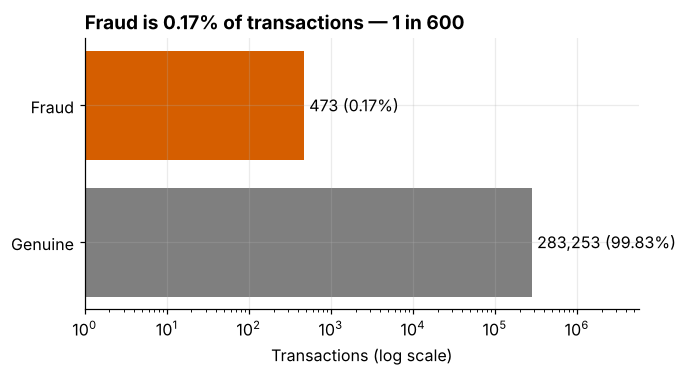

In [4]:
n_f, n = int(y_all.sum()), len(y_all)
print(f"Fraud: {n_f:,} of {n:,} transactions = {100*n_f/n:.3f}%  (1 fraud per {n/n_f:,.0f} transactions)")
do_nothing = L.binary_metrics(yte, np.zeros(len(yte)), 0.5, COST)
trap = pd.DataFrame([do_nothing], index=["Do-nothing (all genuine)"])[["accuracy", "precision", "recall", "f1", "pr_auc", "fn", "cost_inr"]]
display(trap.style.format({"accuracy": "{:.4%}", "cost_inr": "₹{:,.0f}"}))
SUMMARY["fraud_rate_pct"] = 100 * n_f / n; SUMMARY["n_fraud"] = n_f; SUMMARY["n"] = n
SUMMARY["do_nothing_test"] = {k: float(v) for k, v in do_nothing.items()}

fig, ax = plt.subplots(figsize=(6.5, 3.2))
cnt = pd.Series(y_all).value_counts().sort_index()
bars = ax.barh(["Genuine", "Fraud"], cnt.values, color=[L.C["genuine"], L.C["fraud"]])
ax.set_xscale("log"); ax.set_xlabel("Transactions (log scale)")
for b, v in zip(bars, cnt.values): ax.text(v * 1.15, b.get_y() + b.get_height() / 2, f"{v:,} ({100*v/n:.2f}%)", va="center")
ax.set_title(f"Fraud is {100*n_f/n:.2f}% of transactions — 1 in {n/n_f:,.0f}"); ax.set_xlim(1, cnt.max() * 20)
L.savefig(fig, "01_class_imbalance.png", FIG); plt.show()

**Why accuracy misleads:** the do-nothing model is ~99.8% accurate on the test period, yet it catches **zero** fraud and lets every
fraudulent rupee through. From here on we report **precision** (burden on genuine customers), **recall** (fraud stopped),
**F1**, **PR-AUC** (threshold-free ranking quality on the rare class) and **expected ₹ cost**. ROC-AUC appears only with a caveat:
on 0.17% prevalence, 99.9% specificity still means hundreds of false alarms. Section 7 puts the trap next to the real model.

**Leakage columns excluded:** see the table above. Credit card has no post-outcome fields. In UPI, `transaction_status`
is excluded because SUCCESS/FAILED is only known after the payment decision.

## 3 · Diagnosing fraud patterns (PS3) — owner: M. Kumara Swamy
Fraud rates come with **Wilson 95% confidence intervals** and a chi-square test of independence, which matters when a group
holds only a handful of frauds. These are **associations, not causes**.

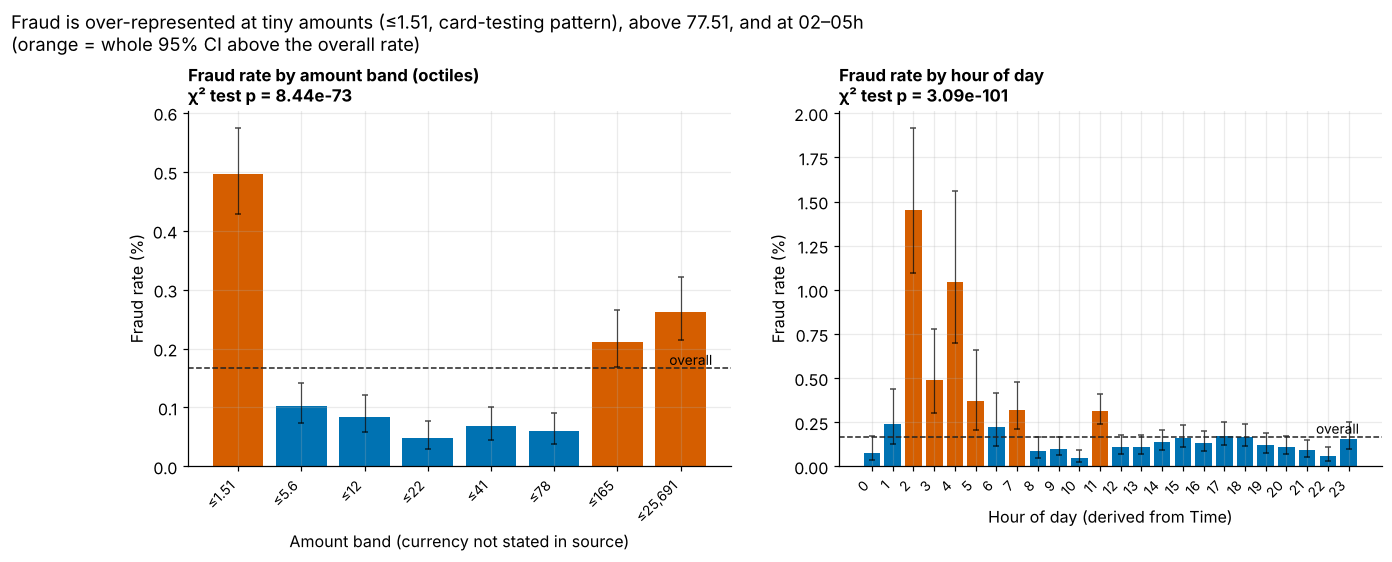

,amount_band,txns,frauds,fraud_rate_pct,ci_lo,ci_hi,share_of_fraud_pct
0,"(-0.001, 1.51]",35654,177,0.496,0.429,0.575,37.421
1,"(1.51, 5.6]",35286,36,0.102,0.074,0.141,7.611
2,"(5.6, 11.5]",35503,30,0.084,0.059,0.121,6.342
3,"(11.5, 22.0]",35532,17,0.048,0.030,0.077,3.594
4,"(22.0, 41.0]",35407,24,0.068,0.046,0.101,5.074
5,"(41.0, 77.51]",35413,21,0.059,0.039,0.091,4.440
6,"(77.51, 165.451]",35465,75,0.211,0.169,0.265,15.856
7,"(165.451, 25691.16]",35466,93,0.262,0.214,0.321,19.662


,amount_zero,txns,frauds,fraud_rate_pct,ci_lo,ci_hi,share_of_fraud_pct
0,0,281918,448,0.159,0.145,0.174,94.715
1,1,1808,25,1.383,0.938,2.033,5.285


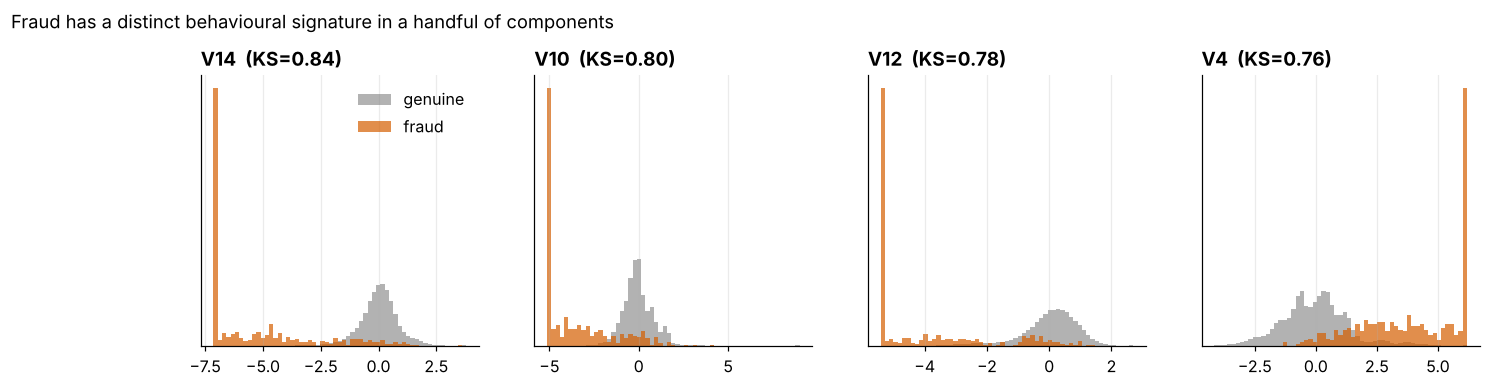

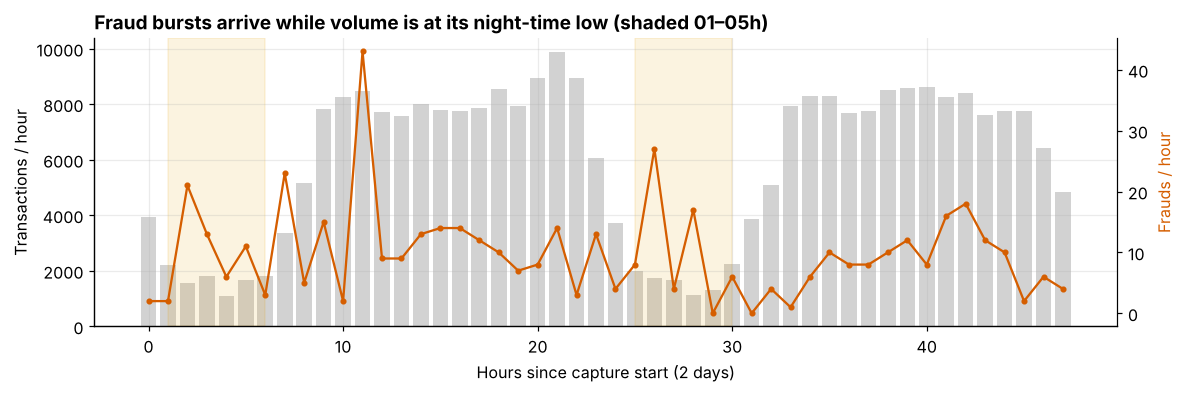

In [5]:
from scipy.stats import chi2_contingency, ks_2samp

def rate_table(col, data=df):
    g = data.groupby(col, observed=True)[TARGET].agg(txns="size", frauds="sum").reset_index()
    g["fraud_rate_pct"] = 100 * g.frauds / g.txns
    lo, hi = L.wilson_ci(g.frauds, g.txns); g["ci_lo"], g["ci_hi"] = 100 * lo, 100 * hi
    p = chi2_contingency(pd.crosstab(data[col], data[TARGET]))[1]
    g["share_of_fraud_pct"] = 100 * g.frauds / g.frauds.sum()
    return g, p

def rate_plot(ax, g, col, title, p, horizontal=False):
    base = 100 * y_all.mean()
    x = np.arange(len(g)); r = g.fraud_rate_pct.values
    err = np.vstack([r - g.ci_lo.values, g.ci_hi.values - r])
    col_ = [L.C["fraud"] if lo > base else L.C["model"] for lo in g.ci_lo.values]
    ax.bar(x, r, yerr=err, color=col_, capsize=2, error_kw=dict(lw=0.8, alpha=0.7))
    ax.axhline(base, color=L.C["ink"], ls="--", lw=1); ax.text(len(g) - 0.5, base, " overall", va="bottom", ha="right", fontsize=9)
    labs = [(f"≤{v.right:,.0f}" if v.right >= 10 else f"≤{v.right:g}") if isinstance(v, pd.Interval) else str(v) for v in g[col]]
    ax.set_xticks(x); ax.set_xticklabels(labs, rotation=0 if len(g) < 8 else 45, ha="center" if len(g) < 8 else "right", fontsize=9)
    ax.set_ylabel("Fraud rate (%)"); ax.set_title(f"{title}\nχ² test p = {p:.3g}", fontsize=11, loc="left")

eda_findings = {}
df["amount_band"] = pd.qcut(df["amount"], 8, duplicates="drop")
if DATASET == "creditcard":
    g_amt, p_amt = rate_table("amount_band"); g_hr, p_hr = rate_table("hour")
    g_zero, p_zero = rate_table("amount_zero"); g_day, p_day = rate_table("day")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    rate_plot(axes[0], g_amt, "amount_band", "Fraud rate by amount band (octiles)", p_amt)
    axes[0].set_xlabel("Amount band (currency not stated in source)")
    rate_plot(axes[1], g_hr, "hour", "Fraud rate by hour of day", p_hr); axes[1].set_xlabel("Hour of day (derived from Time)")
    fig.suptitle("Fraud is over-represented at tiny amounts (≤1.51, card-testing pattern), above 77.51, and at 02–05h\n(orange = whole 95% CI above the overall rate)", x=0.01, y=1.0, va="bottom", ha="left", fontsize=12)
    L.savefig(fig, "02_fraud_by_amount_hour.png", FIG); plt.show()
    display(g_amt.round(3)); display(g_zero.round(3))
    night = df.hour.between(1, 5)
    eda_findings["night_01_05"] = dict(share_txns=100 * night.mean(), share_fraud=100 * y_all[night.values].sum() / n_f,
                                       rate=100 * y_all[night.values].mean(), rate_day=100 * y_all[~night.values].mean())
    eda_findings["amount_bands"] = g_amt[["amount_band", "txns", "frauds", "fraud_rate_pct", "ci_lo", "ci_hi"]].astype({"amount_band": str}).to_dict("records")
    eda_findings["amount_median"] = df.groupby(TARGET)["amount"].median().to_dict()
    eda_findings["amount_zero"] = g_zero.to_dict("records")
    # behaviour signature: which anonymised components separate fraud most (KS statistic)
    ks = pd.Series({c: ks_2samp(df.loc[df[TARGET] == 1, c], df.loc[df[TARGET] == 0, c]).statistic for c in [f"V{i}" for i in range(1, 29)]}).sort_values(ascending=False)
    eda_findings["ks_top"] = ks.head(6).round(3).to_dict()
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
    for ax, c in zip(axes, ks.index[:4]):
        lo, hi = df[c].quantile([0.001, 0.999])
        bins = np.linspace(lo, hi, 60)
        ax.hist(df.loc[df[TARGET] == 0, c].clip(lo, hi), bins=bins, density=True, alpha=0.6, color=L.C["genuine"], label="genuine")
        ax.hist(df.loc[df[TARGET] == 1, c].clip(lo, hi), bins=bins, density=True, alpha=0.7, color=L.C["fraud"], label="fraud")
        ax.set_title(f"{c}  (KS={ks[c]:.2f})"); ax.set_yticks([])
    axes[0].legend(); fig.suptitle("Fraud has a distinct behavioural signature in a handful of components", x=0.01, y=1.0, va="bottom", ha="left", fontsize=12)
    L.savefig(fig, "03_behaviour_signature.png", FIG); plt.show()
    # over time
    hourly = df.assign(abs_hour=(df.Time // 3600).astype(int)).groupby("abs_hour")[TARGET].agg(["size", "sum"])
    fig, ax = plt.subplots(figsize=(12, 3.4)); ax2 = ax.twinx()
    ax.bar(hourly.index, hourly["size"], color=L.C["genuine"], alpha=0.35, label="all txns"); ax.set_ylabel("Transactions / hour")
    ax2.plot(hourly.index, hourly["sum"], color=L.C["fraud"], marker="o", ms=3, lw=1.5, label="frauds"); ax2.set_ylabel("Frauds / hour", color=L.C["fraud"])
    ax2.spines["right"].set_visible(True); ax2.grid(False)
    for s, e in [(1, 6), (25, 30)]: ax.axvspan(s, e, color=L.C["accent"], alpha=0.12)
    ax.set_xlabel("Hours since capture start (2 days)"); ax.set_title("Fraud bursts arrive while volume is at its night-time low (shaded 01–05h)")
    L.savefig(fig, "04_fraud_over_time.png", FIG); plt.show()
else:
    plots = [("transaction type", "Fraud rate by transaction type"), ("merchant_category", "by merchant category"),
             ("amount_band", "by amount band (₹ octiles)"), ("hour", "by hour of day"),
             ("sender_age_group", "by sender age group"), ("device_type", "by device")]
    fig, axes = plt.subplots(2, 3, figsize=(16, 9), gridspec_kw=dict(hspace=0.75, wspace=0.3)); pvals = {}
    for ax, (c, t) in zip(axes.ravel(), plots):
        g, p = rate_table(c); pvals[c] = p; rate_plot(ax, g, c, t, p)
        eda_findings[c] = g[[c, "txns", "frauds", "fraud_rate_pct", "ci_lo", "ci_hi"]].astype({c: str}).to_dict("records")
    fig.suptitle("UPI: no transaction type, merchant, amount, hour or device carries the fraud (the one orange bar does not survive multiple-testing correction)", x=0.01, y=1.0, va="bottom", ha="left", fontsize=12)
    L.savefig(fig, "02_upi_fraud_rates.png", FIG); plt.show()
    allp = {c: chi2_contingency(pd.crosstab(df[c], df[TARGET]))[1] for c in L.UPI_CATS + ["hour", "amount_band", "transaction_status"]}
    pv = pd.Series(allp).sort_values(); bonf = 0.05 / len(pv)
    display(pd.DataFrame({"chi2_p": pv.round(4), f"significant after Bonferroni (p<{bonf:.4f})": pv < bonf}))
    eda_findings["chi2_p"] = pv.round(4).to_dict(); eda_findings["bonferroni_alpha"] = bonf
    g, _ = rate_table("month")
    fig, ax = plt.subplots(figsize=(10, 3.2)); rate_plot(ax, g, "month", "Fraud rate by month of 2024", chi2_contingency(pd.crosstab(df.month, df[TARGET]))[1])
    L.savefig(fig, "04_upi_fraud_by_month.png", FIG); plt.show()
SUMMARY["eda"] = eda_findings

## 4 · Supervised fraud detection (PS4) — owner: M. Kumara Swamy
**Protocol.** Every model is fitted on train, compared on validation and frozen before test is touched. Imbalance handling is compared
per model family: **none** vs **class weights** vs **SMOTE inside an `imblearn.Pipeline`** (synthetic frauds created from the training
fold only). On top of the brief's LR / RF / XGBoost we add LightGBM, CatBoost, Balanced RF, EasyEnsemble, an Optuna-tuned LightGBM,
and two deep tabular models (MLP and FT-Transformer, both trained with focal loss).

**Baselines a fraud-ops team could run with no ML:** (1) a business rule (night and large amount), and (2) a learned 2-split decision tree.

In [6]:
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
SCORES = {}      # name -> dict(val=..., test=...)
META = {}        # name -> family / imbalance / fit time / latency
rules = L.rule_baselines(ds, tr)
for name, (fn, text) in rules.items():
    SCORES[name] = dict(val=fn(Xva), test=fn(Xte)); META[name] = dict(family="Rule baseline", imbalance="n/a", fit_s=0.0)
    print(f"{name}:\n{text}\n")
SUMMARY["rules"] = {k: v[1] for k, v in rules.items()}

zoo = L.build_supervised_zoo(ds, pos_weight, fast=FAST)

def fit_score(name, spec):
    t0 = time.time(); m = spec["model"].fit(Xtr, ytr); fit_s = time.time() - t0
    t1 = time.time(); pv = m.predict_proba(Xva)[:, 1]; lat = (time.time() - t1) / len(Xva) * 1e3
    return dict(val=pv, test=m.predict_proba(Xte)[:, 1], fit_s=fit_s, ms_per_txn=lat, model=m)

FITTED = {}
for name, spec in zoo.items():
    r = cached(f"sup_{name.replace(' ', '').replace('|', '_')}", lambda: fit_score(name, spec))
    SCORES[name] = dict(val=r["val"], test=r["test"]); FITTED[name] = r["model"]
    META[name] = dict(family=spec["family"], imbalance=spec["imbalance"], fit_s=r["fit_s"], ms_per_txn=r["ms_per_txn"])
    print(f"{name:40s} val PR-AUC={average_precision_score(yva, r['val']):.4f}  fit {r['fit_s']:.0f}s")

Rule | night & amount>p95:
FLAG if hour ∈ [0,5] AND amount > 360.00

Rule | learned 2-split tree:
|--- V14 <= -1.63
|   |--- V10 <= -1.88
|   |   |--- class: 1
|   |--- V10 >  -1.88
|   |   |--- class: 1
|--- V14 >  -1.63
|   |--- V4 <= 1.66
|   |   |--- class: 0
|   |--- V4 >  1.66
|   |   |--- class: 0




LogReg | none                            val PR-AUC=0.6081  fit 0s
LogReg | class weights                   val PR-AUC=0.7531  fit 0s
LogReg | SMOTE                           val PR-AUC=0.7047  fit 1s
RandomForest | none                      val PR-AUC=0.7694  fit 108s
RandomForest | class weights             val PR-AUC=0.7664  fit 62s
RandomForest | SMOTE                     val PR-AUC=0.7644  fit 110s
XGBoost | none                           val PR-AUC=0.7755  fit 5s


XGBoost | class weights                  val PR-AUC=0.7829  fit 4s
XGBoost | SMOTE                          val PR-AUC=0.7631  fit 5s
LightGBM | none                          val PR-AUC=0.7696  fit 6s
LightGBM | class weights                 val PR-AUC=0.7711  fit 6s
LightGBM | SMOTE                         val PR-AUC=0.7730  fit 6s
CatBoost | class weights                 val PR-AUC=0.7844  fit 17s


BalancedRF | undersample-bagging         val PR-AUC=0.7665  fit 4s
EasyEnsemble | undersample-boosting      val PR-AUC=0.6544  fit 4s


### 4b · Optuna-tuned LightGBM (tuning on time-series folds inside train, never on validation)

In [7]:
import optuna
from sklearn.model_selection import TimeSeriesSplit
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
optuna.logging.set_verbosity(optuna.logging.WARNING)

def tune_lgbm(n_trials=12 if FAST else 30):
    tss = TimeSeriesSplit(n_splits=3)
    def objective(trial):
        p = dict(n_estimators=trial.suggest_int("n_estimators", 200, 800, step=100),
                 learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                 num_leaves=trial.suggest_int("num_leaves", 8, 64, log=True),
                 min_child_samples=trial.suggest_int("min_child_samples", 20, 300, log=True),
                 colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
                 subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
                 reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
                 scale_pos_weight=trial.suggest_float("scale_pos_weight", 1, pos_weight, log=True))
        aps = []
        for a, b in tss.split(Xtr):
            if ytr[b].sum() == 0: continue
            m = Pipeline([("pre", L.make_preprocessor(ds, False)), ("clf", LGBMClassifier(**p, random_state=L.SEED, n_jobs=-1, verbose=-1))])
            m.fit(Xtr.iloc[a], ytr[a]); aps.append(average_precision_score(ytr[b], m.predict_proba(Xtr.iloc[b])[:, 1]))
        return float(np.mean(aps))
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=L.SEED))
    st.optimize(objective, n_trials=n_trials)
    best = dict(st.best_params, subsample_freq=1)
    m = Pipeline([("pre", L.make_preprocessor(ds, False)), ("clf", LGBMClassifier(**best, random_state=L.SEED, n_jobs=-1, verbose=-1))])
    t0 = time.time(); m.fit(Xtr, ytr); fit_s = time.time() - t0
    t1 = time.time(); pv = m.predict_proba(Xva)[:, 1]; lat = (time.time() - t1) / len(Xva) * 1e3
    return dict(val=pv, test=m.predict_proba(Xte)[:, 1], fit_s=fit_s, ms_per_txn=lat, model=m, params=best, cv_ap=st.best_value)

r = cached("sup_lgbm_optuna", tune_lgbm)
SCORES["LightGBM | Optuna-tuned"] = dict(val=r["val"], test=r["test"]); FITTED["LightGBM | Optuna-tuned"] = r["model"]
META["LightGBM | Optuna-tuned"] = dict(family="LightGBM", imbalance="tuned scale_pos_weight", fit_s=r["fit_s"], ms_per_txn=r["ms_per_txn"])
TUNED_PARAMS = r["params"]; SUMMARY["optuna"] = dict(params=TUNED_PARAMS, inner_cv_pr_auc=r["cv_ap"])
print("best inner-CV PR-AUC:", round(r["cv_ap"], 4), "\nparams:", TUNED_PARAMS)

best inner-CV PR-AUC: 0.7996 
params: {'n_estimators': 300, 'learning_rate': 0.027451173054295157, 'num_leaves': 12, 'min_child_samples': 165, 'colsample_bytree': 0.40482404392189436, 'subsample': 0.9617476746602377, 'reg_lambda': 7.0421341981252095, 'scale_pos_weight': 2.573654603539298, 'subsample_freq': 1}


### 4c · Deep tabular models: MLP and FT-Transformer (Gorishniy et al., 2021), both with focal loss (Lin et al., 2017)
Early stopping uses the last 15% of *train*, never validation. A GPU is used automatically if one is present (e.g. Colab).

In [8]:
for arch, nm in [("mlp", "Deep MLP | focal loss"), ("ftt", "FT-Transformer | focal loss")]:
    def run(arch=arch):
        t0 = time.time(); m = L.TorchTabular(ds, arch=arch, epochs=6 if FAST else 20).fit(Xtr, ytr); fit_s = time.time() - t0
        t1 = time.time(); pv = m.predict_proba(Xva)[:, 1]; lat = (time.time() - t1) / len(Xva) * 1e3
        return dict(val=pv, test=m.predict_proba(Xte)[:, 1], fit_s=fit_s, ms_per_txn=lat, history=m.history)
    r = cached(f"sup_{arch}", run)
    SCORES[nm] = dict(val=r["val"], test=r["test"])
    META[nm] = dict(family="Deep tabular", imbalance="focal loss", fit_s=r["fit_s"], ms_per_txn=r["ms_per_txn"])
    print(f"{nm:32s} val PR-AUC={average_precision_score(yva, r['val']):.4f}  epochs={len(r['history'])}  fit {r['fit_s']:.0f}s")

Deep MLP | focal loss            val PR-AUC=0.7420  epochs=8  fit 6s
FT-Transformer | focal loss      val PR-AUC=0.7067  epochs=6  fit 264s


## 5 · Detecting unknown fraud with label-free anomaly detection (PS5) — owner: V. Naishadh
The detectors are fitted on **training features only, and `y` is never passed in**, mirroring new fraud patterns that have no
labels yet. Labels are used only afterwards, to ask how much fraud sits in the top 1% of anomaly scores.

In [9]:
dets = L.build_anomaly_detectors(ds)
ANOM = {}
for name, det in dets.items():
    def run(det=det):
        t0 = time.time(); det.fit(Xtr); fit_s = time.time() - t0
        return dict(train=det.score(Xtr), val=det.score(Xva), test=det.score(Xte), fit_s=fit_s, det=det)
    r = cached(f"anom_{name.replace(' ', '').replace('(', '').replace(')', '')}", run)
    ANOM[name] = r
    print(f"{name:18s} test PR-AUC={average_precision_score(yte, r['test']):.4f}  fit {r['fit_s']:.0f}s")

# DBSCAN: density clustering on a random 10k sample of test (DBSCAN cannot score unseen points and its neighbour lists grow ~n², so it runs on a sample); points labelled noise (-1) are the anomalies
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
def run_dbscan():
    rng = np.random.default_rng(L.SEED)
    ix = np.sort(np.r_[rng.choice(len(Xte), min(10000, len(Xte)), replace=False)])
    pre = L.make_preprocessor(ds, True).fit(Xtr); Z = pre.transform(Xte.iloc[ix])
    k = 10; dist = NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)[0][:, -1]
    eps = float(np.quantile(dist, 0.99))     # k-distance "knee" ≈ 99th percentile → ~1% noise
    lab = DBSCAN(eps=eps, min_samples=k, n_jobs=1).fit_predict(Z)
    return dict(ix=ix, noise=(lab == -1), eps=eps, n_clusters=int(lab.max() + 1))
db = cached("anom_dbscan", run_dbscan)
yd = yte[db["ix"]]
db_row = dict(detector="DBSCAN (10k test sample)", flagged_pct=100 * db["noise"].mean(),
              fraud_in_sample=int(yd.sum()), fraud_caught=int(yd[db["noise"]].sum()),
              recall=yd[db["noise"]].sum() / max(yd.sum(), 1), precision=yd[db["noise"]].mean() if db["noise"].any() else 0)
print("DBSCAN:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in db_row.items()}, f"eps={db['eps']:.2f}")

Isolation Forest   test PR-AUC=0.0489  fit 1s


ECOD               test PR-AUC=0.0682  fit 3s


COPOD              test PR-AUC=0.0862  fit 1s
LOF (novelty)      test PR-AUC=0.0419  fit 3s
Autoencoder        test PR-AUC=0.0336  fit 3s
DBSCAN: {'detector': 'DBSCAN (10k test sample)', 'flagged_pct': np.float64(0.58), 'fraud_in_sample': 12, 'fraud_caught': 6, 'recall': np.float64(0.5), 'precision': np.float64(0.1034)} eps=8.50


In [10]:
rows = []
for name, r in ANOM.items():
    s = r["test"]
    r1, p1 = L.recall_at_top(yte, s, 0.01); r05, _ = L.recall_at_top(yte, s, 0.005); r5, _ = L.recall_at_top(yte, s, 0.05)
    rows.append(dict(model=name, kind="unsupervised", test_pr_auc=average_precision_score(yte, s), test_roc_auc=roc_auc_score(yte, s),
                     recall_top_0_5pct=r05, recall_top_1pct=r1, precision_top_1pct=p1, recall_top_5pct=r5))
anom_tbl = pd.DataFrame(rows).sort_values("test_pr_auc", ascending=False)
display(anom_tbl.round(4))
anom_tbl.to_csv(os.path.join(TAB, "anomaly_detectors.csv"), index=False)
SUMMARY["anomaly"] = anom_tbl.round(4).to_dict("records"); SUMMARY["dbscan"] = {k: float(v) for k, v in db_row.items() if k != "detector"}
BEST_ANOM = anom_tbl.iloc[0]["model"]

,model,kind,test_pr_auc,test_roc_auc,recall_top_0_5pct,recall_top_1pct,precision_top_1pct,recall_top_5pct
2,COPOD,unsupervised,0.0862,0.9458,0.4865,0.5946,0.0775,0.8378
1,ECOD,unsupervised,0.0682,0.9465,0.4054,0.5811,0.0757,0.8378
0,Isolation Forest,unsupervised,0.0489,0.9561,0.2297,0.5270,0.0687,0.8378
3,LOF (novelty),unsupervised,0.0419,0.5774,0.2838,0.2973,0.0387,0.4054
4,Autoencoder,unsupervised,0.0336,0.9204,0.2432,0.4054,0.0528,0.6351


## 6 · Hybrid model (supervised + anomaly scores), ensemble and model selection
**Hybrid:** the tuned LightGBM is given the label-free anomaly scores (Isolation Forest, ECOD, Autoencoder) as extra features.
The scores are produced by detectors that never saw a label, so no target leaks in. The aim is to make "how unusual is this
transaction?" usable by the supervised model, which helps against fraud that looks unlike past labelled fraud.

**Ensemble:** soft voting (mean predicted probability) over one model from each GBDT library: CatBoost, XGBoost and the tuned LightGBM.
The members are fixed **in advance**, not picked by validation score. Picking the "top 3 on validation" and then judging the ensemble on
that same validation set would be selection bias.

In [11]:
HYB_FEATS = {"Isolation Forest": "anom_iforest", "ECOD": "anom_ecod", "Autoencoder": "anom_ae"}
import copy
ds_h = copy.copy(ds); ds_h.num_features = ds.num_features + list(HYB_FEATS.values())
def add_anom(frame, split):
    f = frame.copy()
    for k, c in HYB_FEATS.items(): f[c] = ANOM[k][split]
    return f
Xtr_h, Xva_h, Xte_h = add_anom(Xtr, "train"), add_anom(Xva, "val"), add_anom(Xte, "test")
def run_hybrid():
    m = Pipeline([("pre", L.make_preprocessor(ds_h, False)), ("clf", LGBMClassifier(**TUNED_PARAMS, random_state=L.SEED, n_jobs=-1, verbose=-1))])
    t0 = time.time(); m.fit(Xtr_h, ytr); fit_s = time.time() - t0
    t1 = time.time(); pv = m.predict_proba(Xva_h)[:, 1]; lat = (time.time() - t1) / len(Xva) * 1e3
    return dict(val=pv, test=m.predict_proba(Xte_h)[:, 1], fit_s=fit_s, ms_per_txn=lat, model=m)
r = cached("sup_hybrid", run_hybrid)
SCORES["Hybrid | tuned LightGBM + anomaly scores"] = dict(val=r["val"], test=r["test"]); FITTED["Hybrid | tuned LightGBM + anomaly scores"] = r["model"]
META["Hybrid | tuned LightGBM + anomaly scores"] = dict(family="Hybrid", imbalance="tuned scale_pos_weight", fit_s=r["fit_s"],
                                                        ms_per_txn=r["ms_per_txn"] + 0.02)   # + anomaly scoring overhead (approx.)

top3 = ["CatBoost | class weights", "XGBoost | class weights", "LightGBM | Optuna-tuned"]      # fixed a priori
ENS = "Ensemble | soft-vote CatBoost+XGB+LGBM"
SCORES[ENS] = dict(val=np.mean([SCORES[k]["val"] for k in top3], 0), test=np.mean([SCORES[k]["test"] for k in top3], 0))
META[ENS] = dict(family="Ensemble", imbalance="inherits", fit_s=sum(META[k]["fit_s"] for k in top3),
                 ms_per_txn=sum(META[k].get("ms_per_txn", 0) for k in top3))
print("Ensemble members:", top3)

Ensemble members: ['CatBoost | class weights', 'XGBoost | class weights', 'LightGBM | Optuna-tuned']


### Model comparison table
**Selection rule (decided before looking at test):**
1. Validation PR-AUC (threshold-free ranking of the rare class).
2. Among models within 0.01 PR-AUC of the best, take the lowest validation ₹ cost at each model's own cost-optimal threshold.
3. Tie-breakers: a single model over an ensemble (latency, explainability), then the fastest.

The test columns are shown for transparency and are **not** used for selection.

In [12]:
rows = []
for k, s in SCORES.items():
    thr, cc = L.best_binary_threshold(yva, s["val"], COST)
    mv = L.binary_metrics(yva, s["val"], thr, COST); mt = L.binary_metrics(yte, s["test"], thr, COST)
    m05 = L.binary_metrics(yte, s["test"], 0.5, COST)
    rows.append(dict(model=k, family=META[k]["family"], imbalance=META[k]["imbalance"],
                     val_pr_auc=mv["pr_auc"], val_cost=mv["cost_inr"], val_thr=thr,
                     test_pr_auc=mt["pr_auc"], test_roc_auc=mt["roc_auc"], test_precision=mt["precision"], test_recall=mt["recall"],
                     test_f1=mt["f1"], test_cost=mt["cost_inr"], test_recall_at_0_5=m05["recall"], test_cost_at_0_5=m05["cost_inr"],
                     fit_s=META[k]["fit_s"], ms_per_txn=META[k].get("ms_per_txn", np.nan)))
cmp = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False).reset_index(drop=True)
cmp.to_csv(os.path.join(TAB, "model_comparison.csv"), index=False)
best_ap = cmp.val_pr_auc.max()
short = cmp[cmp.val_pr_auc >= best_ap - 0.01].copy()
short["is_ensemble"] = short.family.eq("Ensemble")
short = short.sort_values(["val_cost", "is_ensemble", "ms_per_txn"])
FINAL = short.iloc[0]["model"]
display(cmp.style.format({c: "{:.4f}" for c in ["val_pr_auc", "test_pr_auc", "test_roc_auc", "test_precision", "test_recall", "test_f1", "test_recall_at_0_5", "val_thr"]}
                          | {c: "₹{:,.0f}" for c in ["val_cost", "test_cost", "test_cost_at_0_5"]} | {"fit_s": "{:.0f}", "ms_per_txn": "{:.4f}"})
        .apply(lambda r: ["background-color:#fff3cd" if r.model == FINAL else "" for _ in r], axis=1))
print(f"\nShortlist (val PR-AUC within 0.01 of best {best_ap:.4f}):", list(short.model))
print(f"FINAL MODEL → {FINAL}")
SUMMARY["comparison"] = cmp.round(5).to_dict("records"); SUMMARY["final_model"] = FINAL; SUMMARY["shortlist"] = list(short.model)
SUMMARY["ensemble_members"] = top3

# ── Signal check: is the final model's ranking better than chance? (label-permutation test on validation and test)
def perm_p(y_, s_, n=500, seed=L.SEED):
    rng_ = np.random.default_rng(seed); obs = average_precision_score(y_, s_)
    null = np.array([average_precision_score(rng_.permutation(y_), s_) for _ in range(n)])
    return obs, float(null.mean()), float((1 + (null >= obs).sum()) / (n + 1))
sig = {}
for nm_, y_, s_ in [("validation", yva, SCORES[FINAL]["val"]), ("test", yte, SCORES[FINAL]["test"])]:
    obs, nullm, p = perm_p(y_, s_); sig[nm_] = dict(pr_auc=obs, null_mean=nullm, p_value=p)
    print(f"Signal check ({nm_}): PR-AUC {obs:.4f} vs permuted-label mean {nullm:.4f}  →  p = {p:.4f}")
HAS_SIGNAL = sig["test"]["p_value"] < 0.01
print("VERDICT:", "the model ranks fraud far better than chance." if HAS_SIGNAL else
      "NO LEARNABLE SIGNAL — the final model is indistinguishable from random ranking; do not deploy it.")
SUMMARY["signal"] = sig; SUMMARY["has_signal"] = bool(HAS_SIGNAL)

,model,family,imbalance,val_pr_auc,val_cost,val_thr,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,test_cost,test_recall_at_0_5,test_cost_at_0_5,fit_s,ms_per_txn
0,CatBoost | class weights,CatBoost,class weights (√balanced),0.7844,"₹66,300",0.1185,0.7995,0.9684,0.7250,0.7838,0.7532,"₹86,600",0.7568,"₹92,700",17,0.0005
1,XGBoost | class weights,XGBoost,class weights,0.7829,"₹70,900",0.9466,0.7899,0.9757,0.9167,0.7432,0.8209,"₹96,500",0.7568,"₹93,300",4,0.0025
2,Ensemble | soft-vote CatBoost+XGB+LGBM,Ensemble,inherits,0.7808,"₹69,000",0.1525,0.7993,0.9828,0.6517,0.7838,0.7117,"₹89,300",0.7568,"₹92,100",25,0.0114
3,LightGBM | Optuna-tuned,LightGBM,tuned scale_pos_weight,0.7770,"₹67,500",0.2467,0.8007,0.9842,0.7160,0.7838,0.7484,"₹86,900",0.7432,"₹97,700",3,0.0083
4,XGBoost | none,XGBoost,none,0.7755,"₹70,200",0.0376,0.7909,0.9790,0.5842,0.7973,0.6743,"₹87,600",0.7568,"₹91,800",5,0.0027
5,Hybrid | tuned LightGBM + anomaly scores,Hybrid,tuned scale_pos_weight,0.7750,"₹67,500",0.1903,0.7886,0.9832,0.7037,0.7703,0.7355,"₹92,200",0.7297,"₹101,500",3,0.0281
6,LightGBM | SMOTE,LightGBM,SMOTE (in-fold),0.7730,"₹68,700",0.1555,0.7784,0.9779,0.5321,0.7838,0.6339,"₹95,300",0.7432,"₹98,300",6,0.0150
7,LightGBM | class weights,LightGBM,class weights (√ratio),0.7711,"₹72,600",0.0269,0.7940,0.9879,0.5842,0.7973,0.6743,"₹87,600",0.7297,"₹104,800",6,0.0159
8,LightGBM | none,LightGBM,none,0.7696,"₹73,000",0.2998,0.7992,0.9827,0.8852,0.7297,0.8000,"₹102,100",0.7027,"₹112,100",6,0.0141
9,RandomForest | none,Random Forest,none,0.7694,"₹66,900",0.1761,0.7866,0.9438,0.7403,0.7703,0.7550,"₹91,000",0.6486,"₹131,200",108,0.0056



Shortlist (val PR-AUC within 0.01 of best 0.7844): ['CatBoost | class weights', 'LightGBM | Optuna-tuned', 'Hybrid | tuned LightGBM + anomaly scores', 'Ensemble | soft-vote CatBoost+XGB+LGBM', 'XGBoost | none', 'XGBoost | class weights']
FINAL MODEL → CatBoost | class weights


Signal check (validation): PR-AUC 0.7844 vs permuted-label mean 0.0012  →  p = 0.0020


Signal check (test): PR-AUC 0.7995 vs permuted-label mean 0.0015  →  p = 0.0020
VERDICT: the model ranks fraud far better than chance.


### Weighting vs SMOTE: does SMOTE beat class weights on PR-AUC and cost?

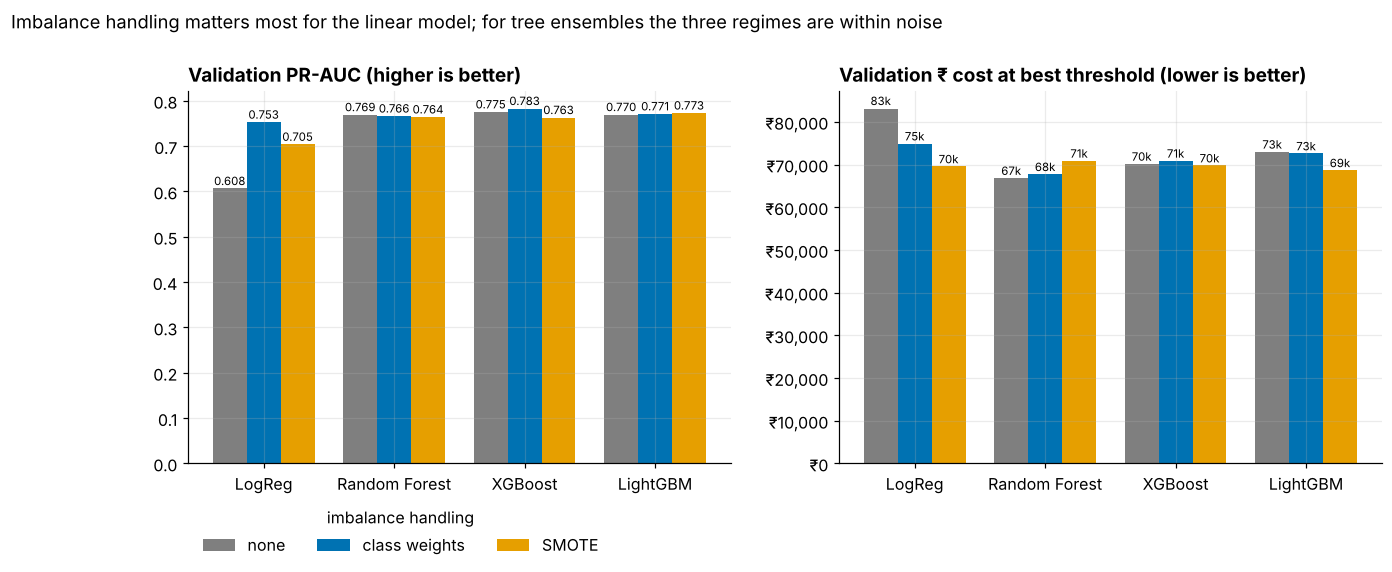

In [13]:
fams = ["Logistic Regression", "Random Forest", "XGBoost", "LightGBM"]
sub = cmp[cmp.family.isin(fams) & ~cmp.model.str.contains("Optuna")].copy()
sub["regime"] = sub.imbalance.str.replace(r" \(.*\)", "", regex=True).replace({"class weights": "class weights"})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
short_names = {"Logistic Regression": "LogReg", "Random Forest": "Random Forest", "XGBoost": "XGBoost", "LightGBM": "LightGBM"}
regimes = ["none", "class weights", "SMOTE"]; w = 0.26
for j, (metric, lab) in enumerate([("val_pr_auc", "Validation PR-AUC (higher is better)"), ("val_cost", "Validation ₹ cost at best threshold (lower is better)")]):
    ax = axes[j]
    for i, rg in enumerate(regimes):
        vals = [sub[(sub.family == f) & (sub.regime == rg)][metric].mean() for f in fams]
        b = ax.bar(np.arange(len(fams)) + (i - 1) * w, vals, w, label=rg, color=[L.C["genuine"], L.C["model"], L.C["accent"]][i])
        for xx, v in zip(np.arange(len(fams)) + (i - 1) * w, vals):
            ax.text(xx, v * 1.01, f"{v:.3f}" if metric == "val_pr_auc" else f"{v/1000:.0f}k", ha="center", fontsize=7.5)
    ax.set_xticks(range(len(fams))); ax.set_xticklabels([short_names[f] for f in fams]); ax.set_title(lab)
    if metric == "val_cost": ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: L.inr(v)))
axes[0].legend(title="imbalance handling", ncol=3, loc="upper left", bbox_to_anchor=(0, -0.08))
fig.suptitle("Imbalance handling matters most for the linear model; for tree ensembles the three regimes are within noise", x=0.01, y=1.0, va="bottom", ha="left", fontsize=12)
L.savefig(fig, "05_weights_vs_smote.png", FIG); plt.show()
SUMMARY["imbalance_compare"] = sub[["model", "family", "regime", "val_pr_auc", "val_cost", "test_pr_auc", "test_cost"]].round(4).to_dict("records")

### Model comparison: combined and individual views
**Combined:**
1. Every model's test PR-AUC with a bootstrap 95% CI, next to its validation PR-AUC. Overlapping intervals mean the difference is noise.
2. A metric heat-table across all models.

**Individual:** one precision–recall panel per model (test solid, validation dashed).

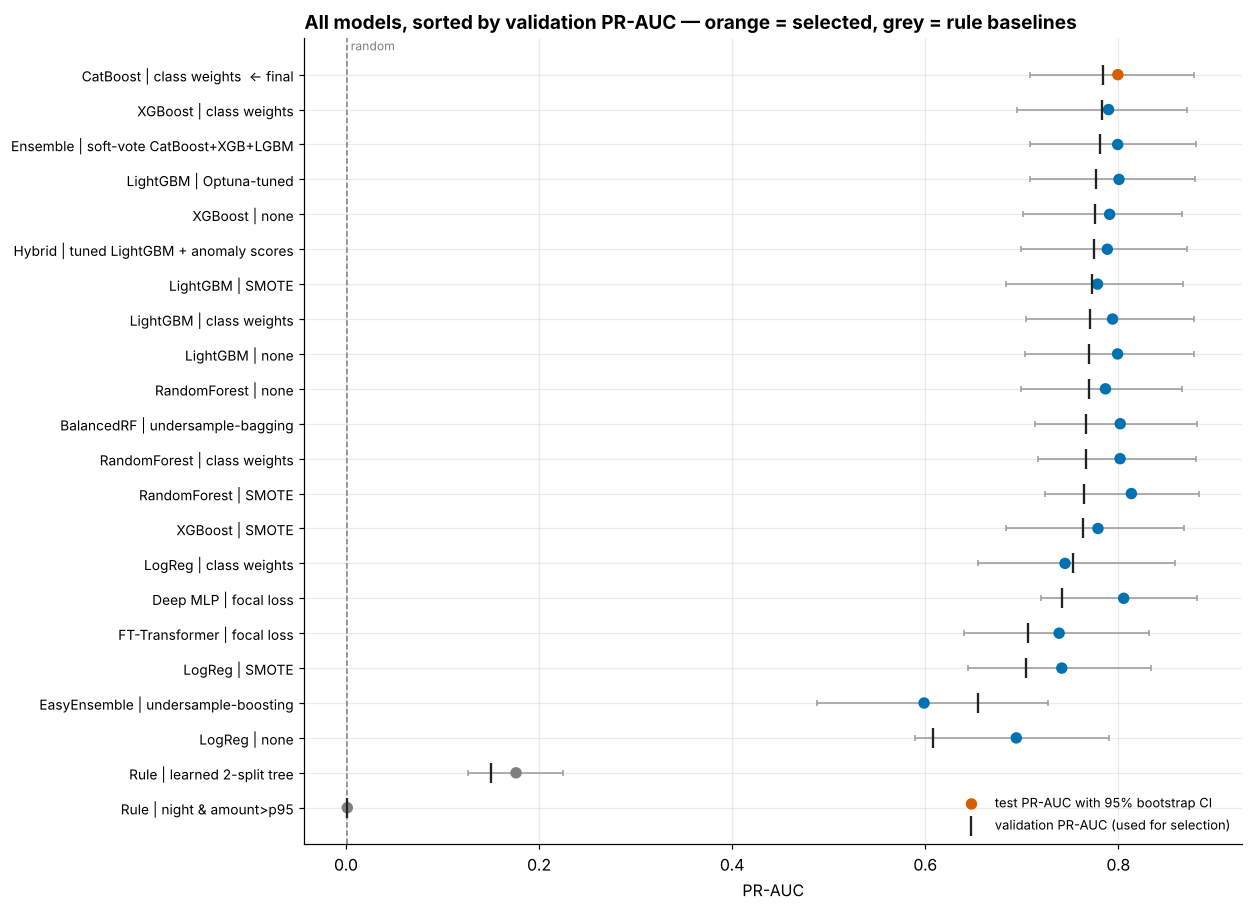

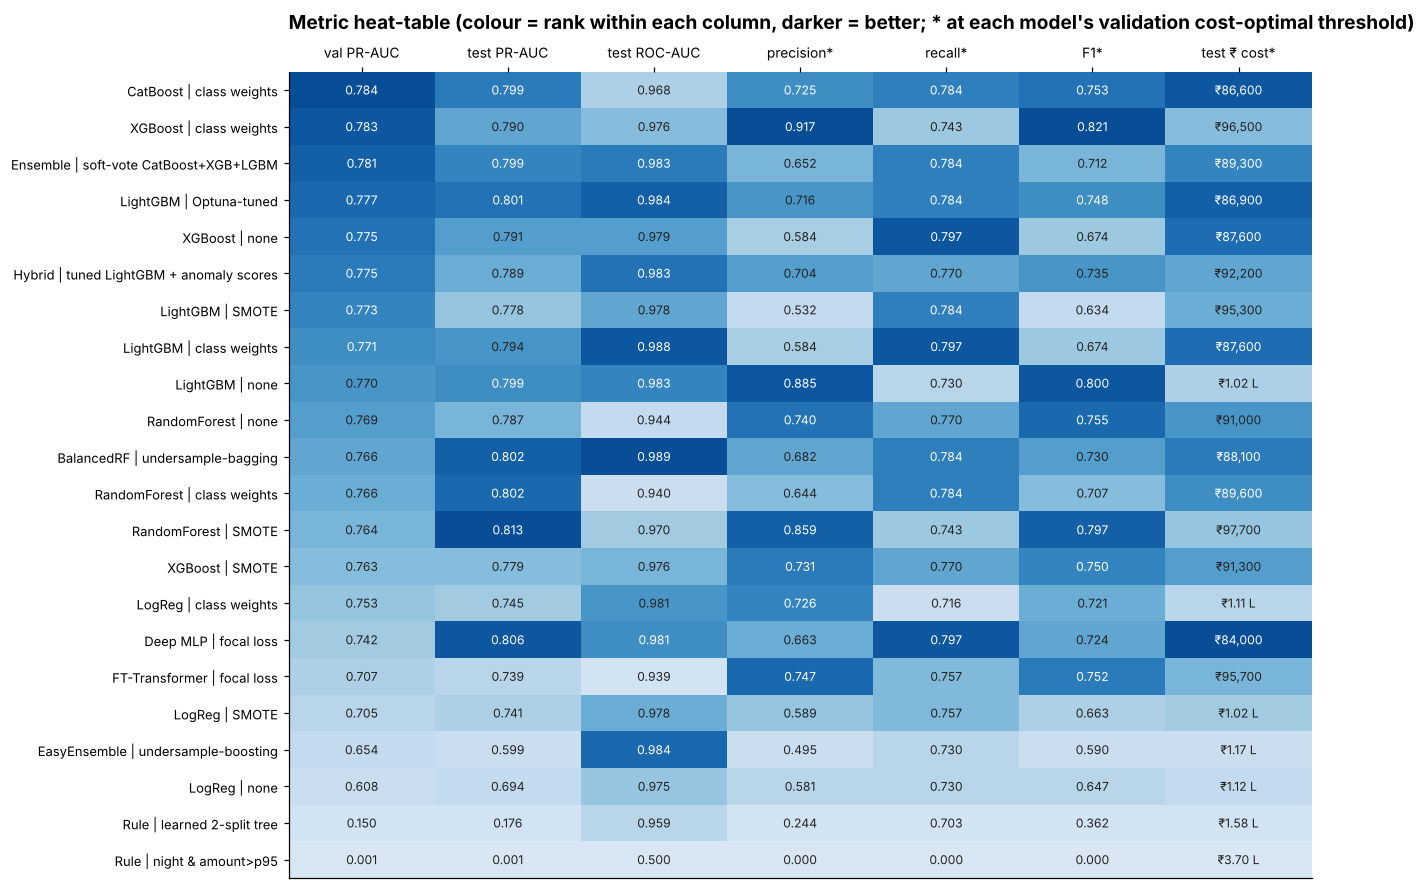

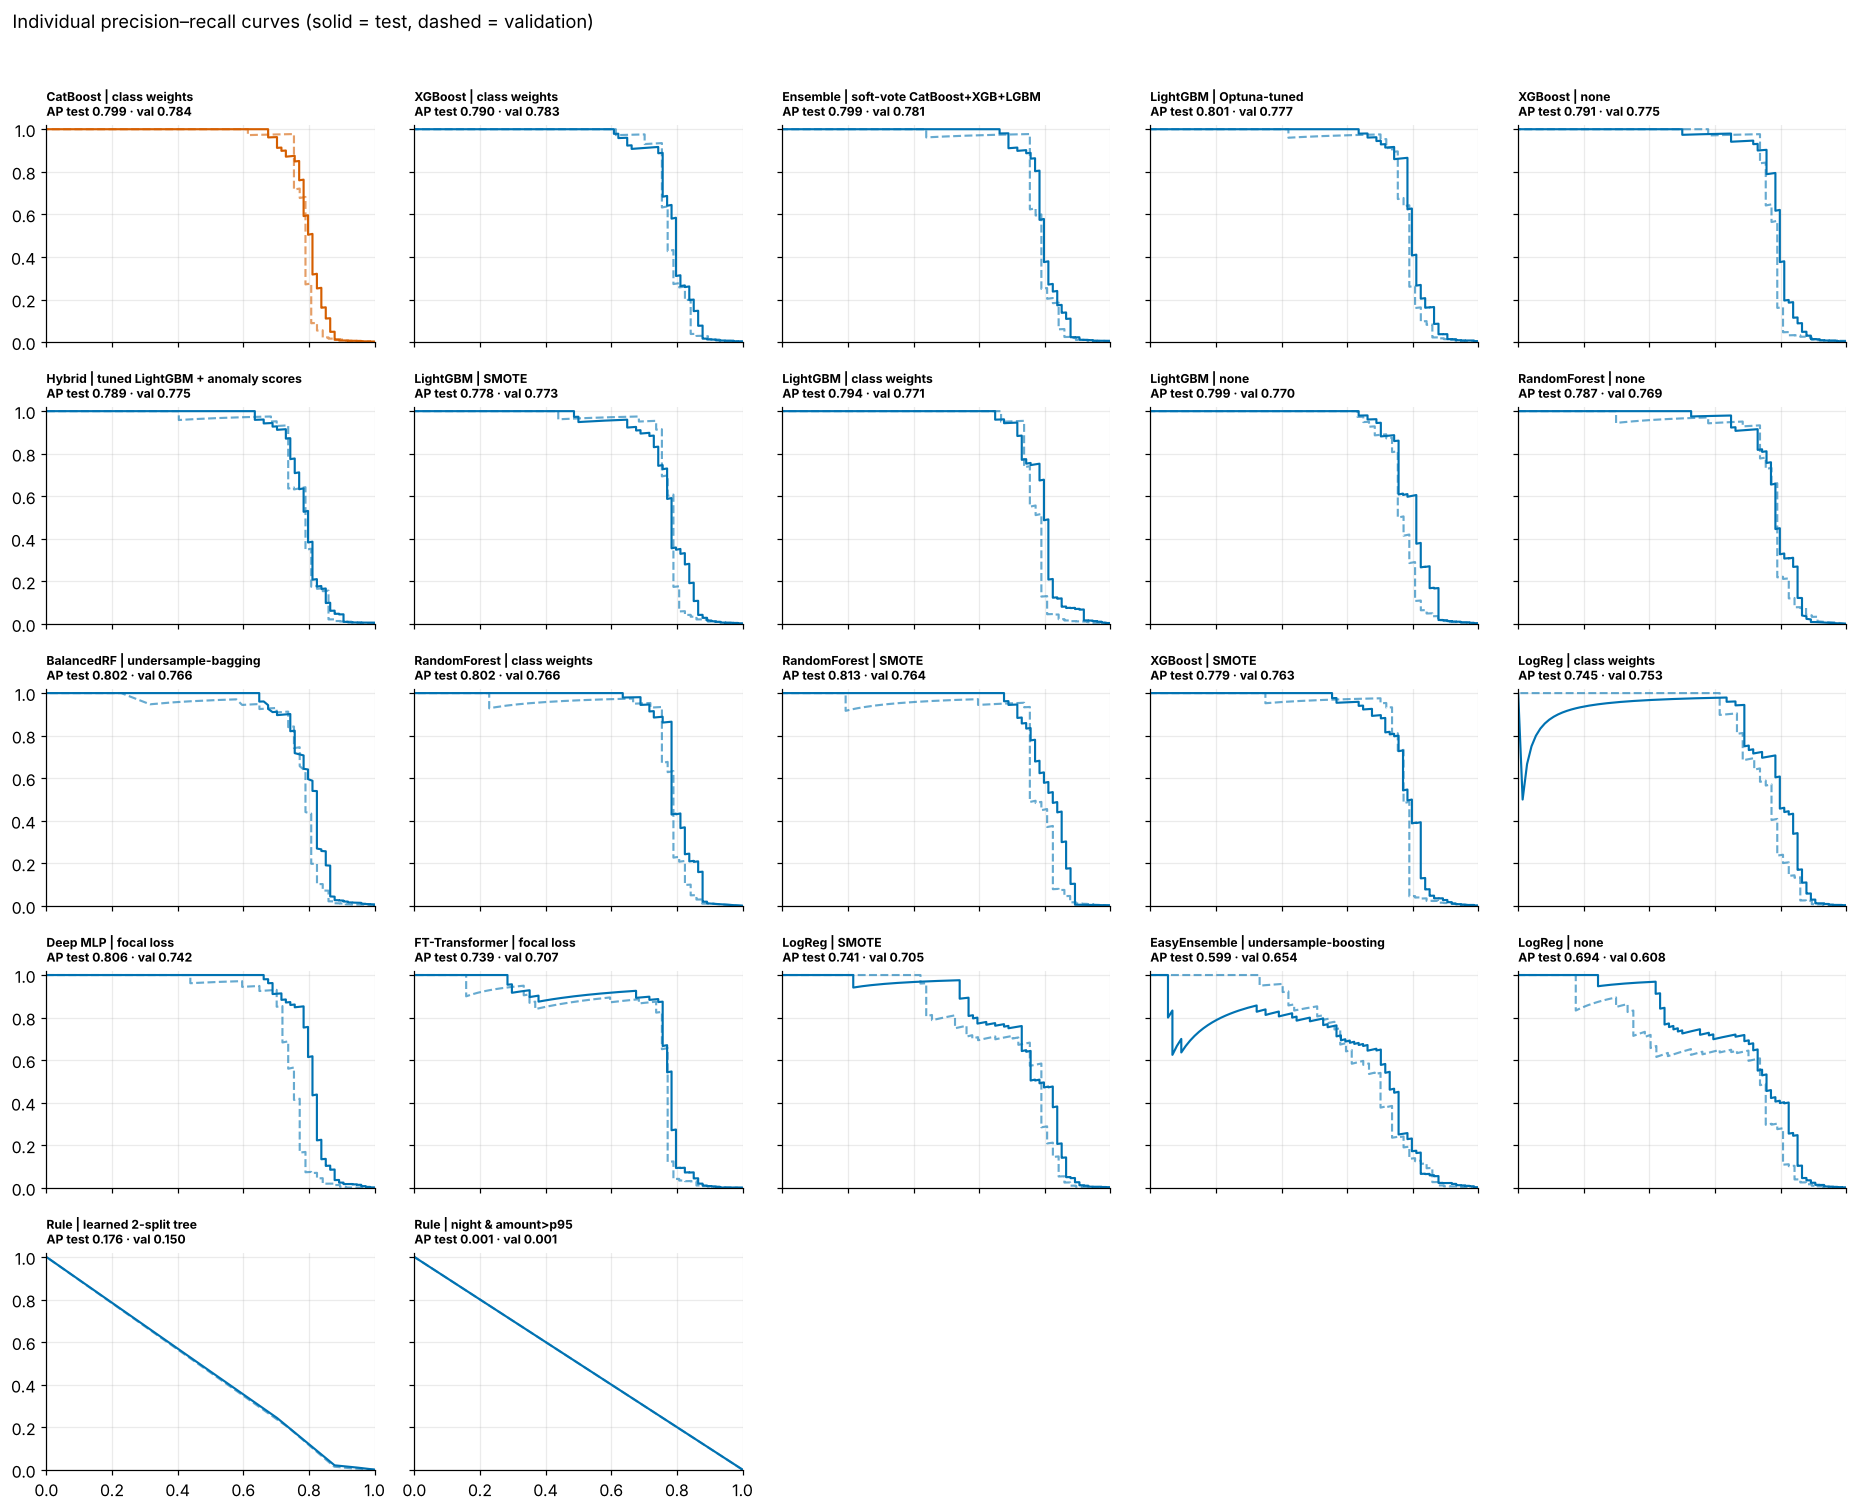

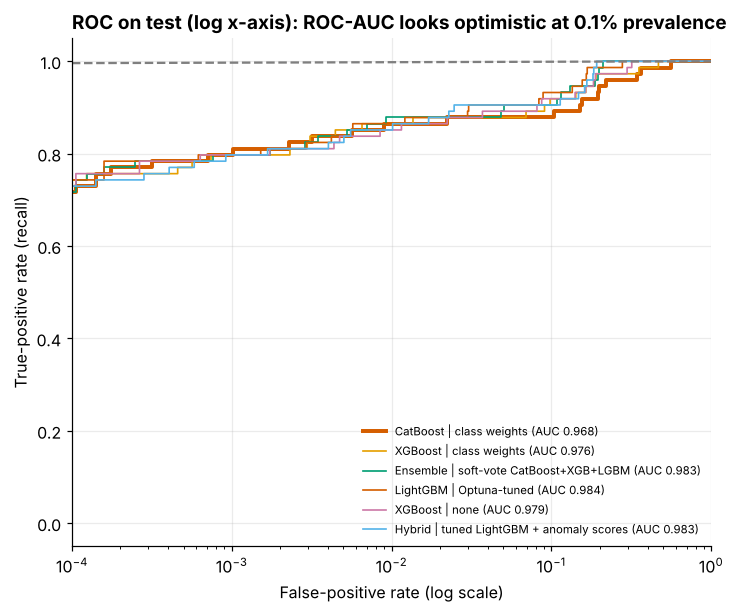

In [14]:
order_m = list(cmp.model)
def _ci(m):
    s_ = SCORES[m]["test"]
    return L.bootstrap_ci(yte, s_, lambda y_, s2: average_precision_score(y_, s2), n_boot=200)
ci_rows = [(m, average_precision_score(yte, SCORES[m]["test"]), *_ci(m), average_precision_score(yva, SCORES[m]["val"])) for m in order_m]
cidf = pd.DataFrame(ci_rows, columns=["model", "test_pr_auc", "ci_lo", "ci_hi", "val_pr_auc"])
cidf.to_csv(os.path.join(TAB, "model_pr_auc_ci.csv"), index=False)
SUMMARY["pr_auc_ci"] = cidf.round(4).to_dict("records")

fig, ax = plt.subplots(figsize=(11, 0.36 * len(cidf) + 1.6))
yy = np.arange(len(cidf))[::-1]
cols = [L.C["fraud"] if m == FINAL else (L.C["genuine"] if m.startswith("Rule") else L.C["model"]) for m in cidf.model]
ax.errorbar(cidf.test_pr_auc, yy, xerr=[cidf.test_pr_auc - cidf.ci_lo, cidf.ci_hi - cidf.test_pr_auc], fmt="none", ecolor="#9a9a9a", capsize=2, lw=1)
ax.scatter(cidf.test_pr_auc, yy, color=cols, s=42, zorder=3, label="test PR-AUC with 95% bootstrap CI")
ax.scatter(cidf.val_pr_auc, yy, marker="|", s=160, color=L.C["ink"], zorder=4, label="validation PR-AUC (used for selection)")
ax.axvline(yte.mean(), ls="--", color=L.C["genuine"], lw=1); ax.text(yte.mean(), len(cidf) - 0.3, " random", fontsize=8, color=L.C["genuine"])
ax.set_yticks(yy); ax.set_yticklabels([m + ("  ← final" if m == FINAL else "") for m in cidf.model], fontsize=9)
ax.set_xlabel("PR-AUC"); ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("All models, sorted by validation PR-AUC — orange = selected, grey = rule baselines" if HAS_SIGNAL else
             "All models sit at the random line — no model is distinguishable from chance")
L.savefig(fig, "05b_all_models_pr_auc_ci.png", FIG); plt.show()

# metric heat-table
mcols = ["val_pr_auc", "test_pr_auc", "test_roc_auc", "test_precision", "test_recall", "test_f1", "test_cost"]
H = cmp.set_index("model")[mcols]
Hn = H.rank(pct=True); Hn["test_cost"] = 1 - H["test_cost"].rank(pct=True) + 1 / len(H)   # rank colouring: rule rows no longer flatten the scale
fig, ax = plt.subplots(figsize=(12, 0.36 * len(H) + 1.6)); ax.grid(False)
ax.imshow(Hn.values, cmap="Blues", aspect="auto", vmin=-0.15, vmax=1.15)
for i in range(H.shape[0]):
    for j, c in enumerate(mcols):
        v = H.values[i, j]
        ax.text(j, i, L.inr(v) if c == "test_cost" else f"{v:.3f}", ha="center", va="center", fontsize=8,
                color="white" if Hn.values[i, j] > 0.65 else L.C["ink"])
ax.set_xticks(range(len(mcols))); ax.set_xticklabels(["val PR-AUC", "test PR-AUC", "test ROC-AUC", "precision*", "recall*", "F1*", "test ₹ cost*"], fontsize=9)
ax.set_yticks(range(len(H))); ax.set_yticklabels(H.index, fontsize=8.5); ax.xaxis.tick_top()
ax.set_title("Metric heat-table (colour = rank within each column, darker = better; * at each model's validation cost-optimal threshold)", pad=28)
L.savefig(fig, "05c_metric_heat_table.png", FIG); plt.show()

# individual PR panels
ms = [m for m in order_m]
nc = 5; nr = int(np.ceil(len(ms) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(3.4 * nc, 2.7 * nr), sharex=True, sharey=True)
for ax, m in zip(axes.ravel(), ms):
    for split, yv_, ls_ in [("test", yte, "-"), ("val", yva, "--")]:
        p_, r_, _ = precision_recall_curve(yv_, SCORES[m][split])
        ax.plot(r_, p_, ls=ls_, lw=1.4, color=L.C["fraud"] if m == FINAL else L.C["model"], alpha=1 if split == "test" else 0.6)
    ax.set_title(f"{m}\nAP test {average_precision_score(yte, SCORES[m]['test']):.3f} · val {average_precision_score(yva, SCORES[m]['val']):.3f}", fontsize=8, loc="left")
    ax.set_ylim(0, 1.02); ax.set_xlim(0, 1)
for ax in axes.ravel()[len(ms):]: ax.set_visible(False)
fig.suptitle("Individual precision–recall curves (solid = test, dashed = validation)", x=0.01, y=1.0, va="bottom", ha="left", fontsize=12)
fig.tight_layout(); L.savefig(fig, "05d_individual_pr_curves.png", FIG); plt.show()

# combined ROC (with the imbalance caveat)
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(7.5, 6))
for i, m in enumerate([FINAL] + [x for x in order_m[:6] if x != FINAL]):
    fpr, tpr, _ = roc_curve(yte, SCORES[m]["test"])
    ax.plot(fpr, tpr, lw=2.6 if m == FINAL else 1.1, color=L.C["fraud"] if m == FINAL else L.PALETTE[i % 6], label=f"{m} (AUC {roc_auc_score(yte, SCORES[m]['test']):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=L.C["genuine"]); ax.set_xscale("log"); ax.set_xlim(1e-4, 1)
ax.set_xlabel("False-positive rate (log scale)"); ax.set_ylabel("True-positive rate (recall)"); ax.legend(fontsize=7.5, loc="lower right")
ax.set_title("ROC on test (log x-axis): ROC-AUC looks optimistic at 0.1% prevalence")
L.savefig(fig, "05e_roc_curves.png", FIG); plt.show()

### Supervised vs anomaly: how much fraud does a label-free detector find in its top 1%?

Test frauds=74 | caught in top-1% → supervised 63, COPOD 44, anomaly-only 1, both 43


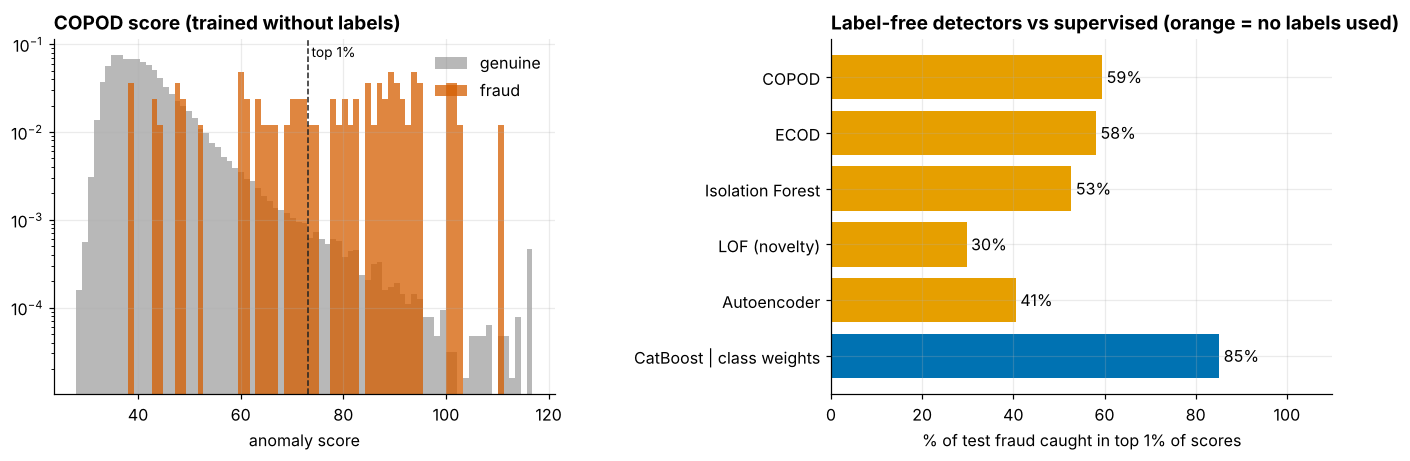

In [15]:
s_fin = SCORES[FINAL]["test"]; s_an = ANOM[BEST_ANOM]["test"]
k1 = int(np.ceil(0.01 * len(yte)))
top_sup = set(np.argsort(-s_fin)[:k1]); top_an = set(np.argsort(-s_an)[:k1]); fr = set(np.where(yte == 1)[0])
overlap = dict(fraud_total=len(fr), sup_top1=len(fr & top_sup), anom_top1=len(fr & top_an),
               anom_only=len((fr & top_an) - top_sup), sup_only=len((fr & top_sup) - top_an), both=len(fr & top_sup & top_an))
print(f"Test frauds={len(fr)} | caught in top-1% → supervised {overlap['sup_top1']}, {BEST_ANOM} {overlap['anom_top1']}, "
      f"anomaly-only {overlap['anom_only']}, both {overlap['both']}")
SUMMARY["sup_vs_anom_top1"] = overlap; SUMMARY["best_anomaly"] = BEST_ANOM

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw=dict(wspace=0.55))
ax = axes[0]; s = ANOM[BEST_ANOM]["test"]; lo, hi = np.quantile(s, [0.0, 0.9995])
bins = np.linspace(lo, hi, 80)
ax.hist(s[yte == 0].clip(lo, hi), bins, density=True, alpha=0.55, color=L.C["genuine"], label="genuine")
ax.hist(s[yte == 1].clip(lo, hi), bins, density=True, alpha=0.75, color=L.C["fraud"], label="fraud")
ax.axvline(np.quantile(s, 0.99), color=L.C["ink"], ls="--", lw=1); ax.text(np.quantile(s, 0.99), ax.get_ylim()[1] * 0.9, " top 1%", fontsize=9)
ax.set_yscale("log"); ax.set_title(f"{BEST_ANOM} score (trained without labels)"); ax.legend(); ax.set_xlabel("anomaly score")
ax = axes[1]
lab = list(anom_tbl.model) + [FINAL]; vals = list(anom_tbl.recall_top_1pct) + [overlap["sup_top1"] / max(len(fr), 1)]
cols = [L.C["accent"]] * len(anom_tbl) + [L.C["model"]]
ax.barh(lab[::-1], np.array(vals[::-1]) * 100, color=cols[::-1])
for i, v in enumerate(vals[::-1]): ax.text(v * 100 + 1, i, f"{v*100:.0f}%", va="center")
ax.set_xlim(0, 110); ax.set_xlabel("% of test fraud caught in top 1% of scores"); ax.set_title("Label-free detectors vs supervised (orange = no labels used)")
L.savefig(fig, "06_anomaly_vs_supervised.png", FIG); plt.show()

## 7 · Precision–recall curves & the cost-based threshold (PS6) — owner: V. Naishadh
Expected cost = missed fraud × ₹X + false blocks × ₹Y. The threshold that minimises it is chosen on **validation**, then frozen
and reported on **test**, alongside the default 0.5.

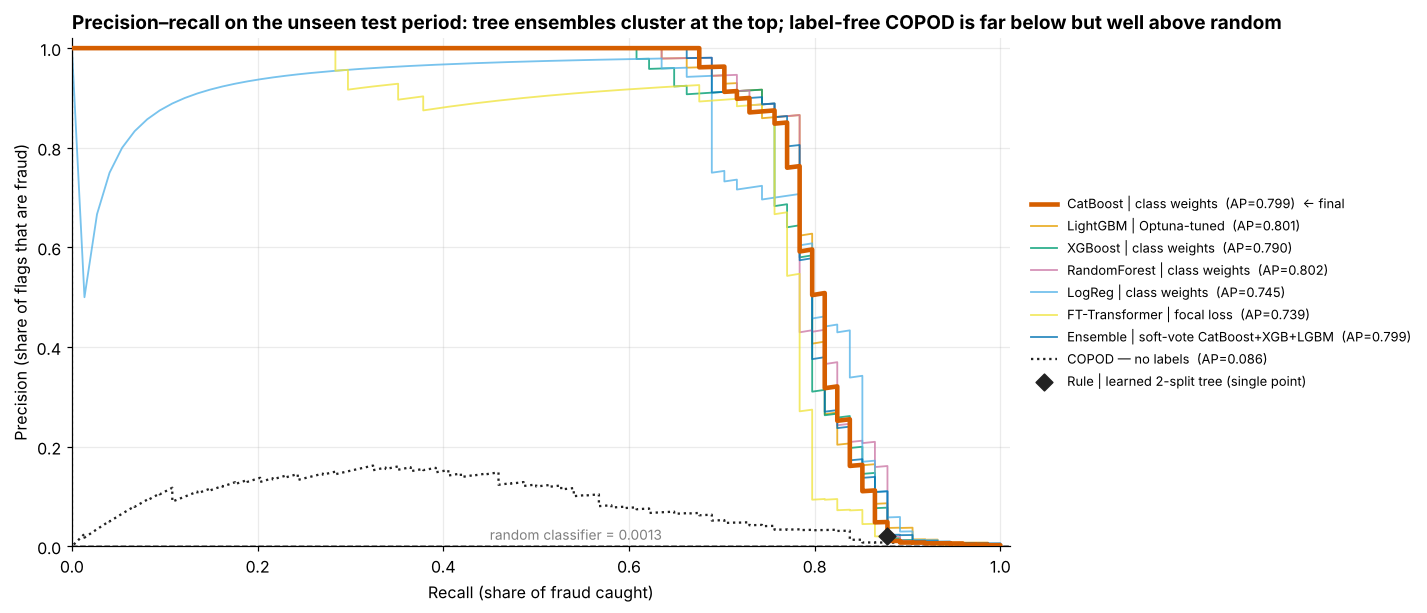

In [16]:
show = list(dict.fromkeys([FINAL, "LightGBM | Optuna-tuned", "XGBoost | class weights", "RandomForest | class weights",
                           "CatBoost | class weights", "LogReg | class weights", "FT-Transformer | focal loss", ENS]))
show = [m for m in show if m in SCORES]
fig, ax = plt.subplots(figsize=(11, 6))
others = [c for c in L.PALETTE if c not in (L.C["fraud"], "#000000", "#7F7F7F")]
for i, m in enumerate(show):
    p, r, _ = precision_recall_curve(yte, SCORES[m]["test"]); ap = average_precision_score(yte, SCORES[m]["test"])
    ax.plot(r, p, lw=3 if m == FINAL else 1.2, color=L.C["fraud"] if m == FINAL else others[i % len(others)],
            alpha=1 if m == FINAL else 0.8, label=f"{m}  (AP={ap:.3f})" + ("  ← final" if m == FINAL else ""), zorder=5 if m == FINAL else 2)
p, r, _ = precision_recall_curve(yte, ANOM[BEST_ANOM]["test"])
ax.plot(r, p, ls=":", color=L.C["ink"], lw=1.5, label=f"{BEST_ANOM} — no labels  (AP={average_precision_score(yte, ANOM[BEST_ANOM]['test']):.3f})")
rule = list(rules)[1]; mt = L.binary_metrics(yte, SCORES[rule]["test"], 0.5)
ax.scatter([mt["recall"]], [mt["precision"]], marker="D", s=60, color=L.C["ink"], zorder=6, label=f"{rule} (single point)")
ax.axhline(yte.mean(), color=L.C["genuine"], ls="--", lw=1); ax.text(0.45, yte.mean() + 0.012, f"random classifier = {yte.mean():.4f}", fontsize=9, color=L.C["genuine"])
ax.set_xlabel("Recall (share of fraud caught)"); ax.set_ylabel("Precision (share of flags that are fraud)")
ax.legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.01, 0.5)); ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.02)
if HAS_SIGNAL:
    ax.set_title(f"Precision–recall on the unseen test period: tree ensembles cluster at the top; label-free {BEST_ANOM} is far below but well above random")
else:
    ax.set_ylim(0, 0.02)
    ax.set_title(f"Every model's precision sits on the random line ({yte.mean():.4f}) — no learnable signal (y-axis zoomed to 0–2%)")
L.savefig(fig, "07_pr_curves.png", FIG); plt.show()

,accuracy,precision,recall,f1,tp,fp,fn,cost_inr
Do-nothing (approve all),99.8696%,0.000,0.000,0.000,0,0,74,"₹370,000"
CatBoost | class weights @ default 0.5,99.9524%,0.862,0.757,0.806,56,9,18,"₹92,700"
CatBoost | class weights @ cost threshold 0.1185,99.9330%,0.725,0.784,0.753,58,22,16,"₹86,600"


Test PR-AUC 0.7995 (95% CI 0.708–0.878) | recall 0.784 (CI 0.676–0.865) | cost ₹86,600 (CI ₹54,500–₹1.27 L)


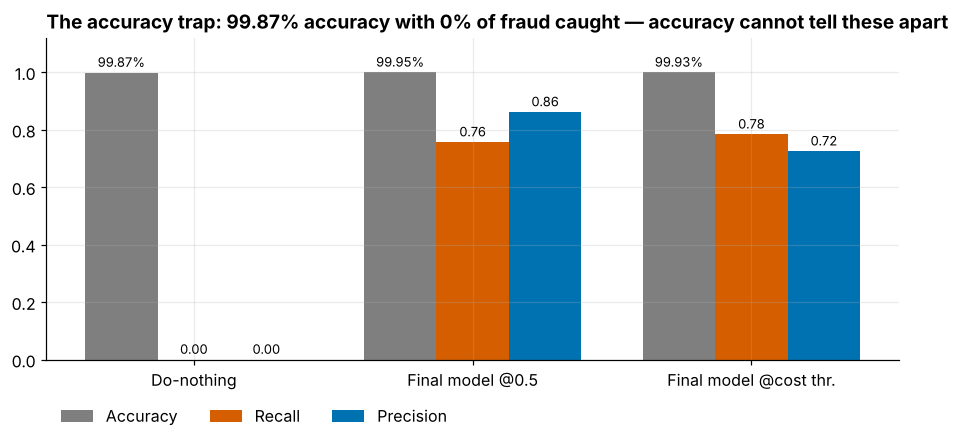

In [17]:
sv, st_ = SCORES[FINAL]["val"], SCORES[FINAL]["test"]
T_COST, cc_val = L.best_binary_threshold(yva, sv, COST)
cc_test = L.cost_curve(yte, st_, COST)
m_def, m_cost = L.binary_metrics(yte, st_, 0.5, COST), L.binary_metrics(yte, st_, T_COST, COST)
approve_all_cost = yte.sum() * COST.X
res = pd.DataFrame([do_nothing, m_def, m_cost], index=["Do-nothing (approve all)", f"{FINAL} @ default 0.5", f"{FINAL} @ cost threshold {T_COST:.4f}"])
display(res[["accuracy", "precision", "recall", "f1", "tp", "fp", "fn", "cost_inr"]].style.format({"accuracy": "{:.4%}", "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "cost_inr": "₹{:,.0f}"}))
ci_cost = L.bootstrap_ci(yte, st_, lambda y_, s_: L.binary_metrics(y_, s_, T_COST, COST)["cost_inr"], n_boot=400)
ci_ap = L.bootstrap_ci(yte, st_, lambda y_, s_: average_precision_score(y_, s_), n_boot=1000)
ci_rec = L.bootstrap_ci(yte, st_, lambda y_, s_: L.binary_metrics(y_, s_, T_COST, COST)["recall"], n_boot=400)
print(f"Test PR-AUC {m_cost['pr_auc']:.4f} (95% CI {ci_ap[0]:.3f}–{ci_ap[1]:.3f}) | recall {m_cost['recall']:.3f} (CI {ci_rec[0]:.3f}–{ci_rec[1]:.3f}) | cost {L.inr(m_cost['cost_inr'])} (CI {L.inr(ci_cost[0])}–{L.inr(ci_cost[1])})")
SUMMARY["threshold"] = dict(t_cost=T_COST, test_default=m_def, test_cost=m_cost, approve_all_cost=float(approve_all_cost),
                            ci_pr_auc=ci_ap, ci_cost=ci_cost, ci_recall=ci_rec, bayes_threshold_if_calibrated=COST.Y / (COST.X + COST.Y))

# accuracy trap chart
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = ["Do-nothing", "Final model @0.5", "Final model @cost thr."]
mets = [("accuracy", "Accuracy"), ("recall", "Recall"), ("precision", "Precision")]
w = 0.26
for i, (k, lab) in enumerate(mets):
    vals = [d[k] for d in [do_nothing, m_def, m_cost]]
    b = ax.bar(np.arange(3) + (i - 1) * w, vals, w, label=lab, color=[L.C["genuine"], L.C["fraud"], L.C["model"]][i])
    for xx, v in zip(np.arange(3) + (i - 1) * w, vals): ax.text(xx, v + 0.02, f"{v:.2%}" if k == "accuracy" else f"{v:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(3)); ax.set_xticklabels(labels); ax.set_ylim(0, 1.12); ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.1))
ax.set_title(f"The accuracy trap: {do_nothing['accuracy']:.2%} accuracy with 0% of fraud caught — accuracy cannot tell these apart")
L.savefig(fig, "08_accuracy_trap.png", FIG); plt.show()

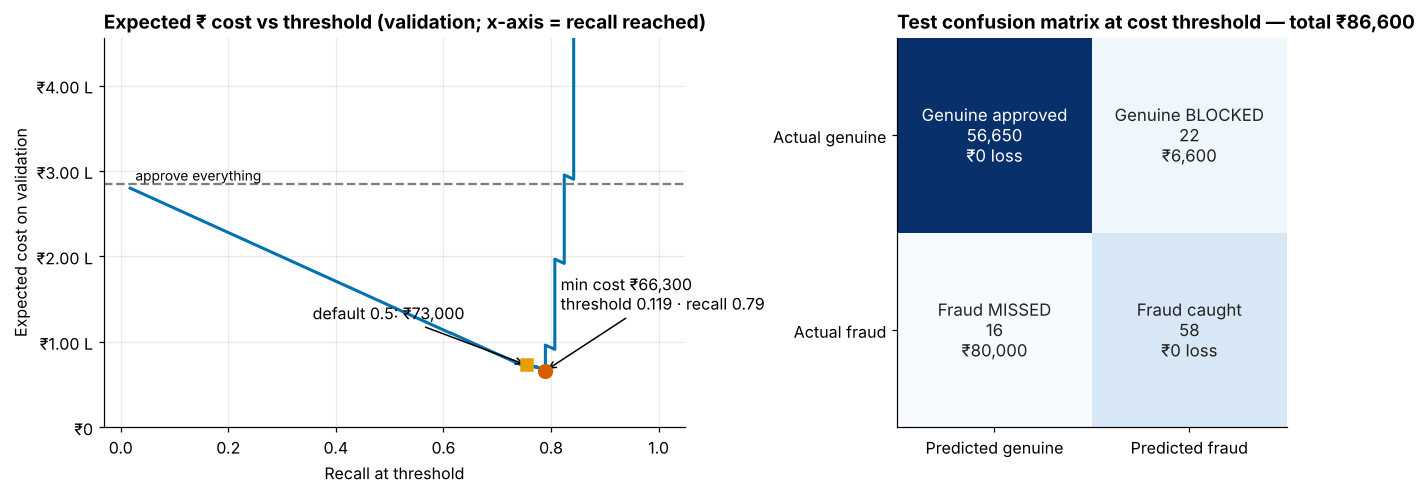

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
ax = axes[0]
ccv = cc_val[cc_val.threshold < np.inf]
ax.plot(ccv.recall, ccv.cost, color=L.C["model"], lw=2)
i0 = ccv.cost.idxmin(); ax.scatter(ccv.recall[i0], ccv.cost[i0], s=80, color=L.C["fraud"], zorder=5)
ax.annotate(f"min cost {L.inr(ccv.cost[i0])}\nthreshold {T_COST:.3f} · recall {ccv.recall[i0]:.2f}", (ccv.recall[i0], ccv.cost[i0]),
            xytext=(10, 40), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
m05v = L.binary_metrics(yva, sv, 0.5, COST)
ax.scatter([m05v["recall"]], [m05v["cost_inr"]], marker="s", s=70, color=L.C["accent"], zorder=5)
ax.annotate(f"default 0.5: {L.inr(m05v['cost_inr'])}", (m05v["recall"], m05v["cost_inr"]), xytext=(-140, 30), textcoords="offset points", arrowprops=dict(arrowstyle="->"))
ax.axhline(yva.sum() * COST.X, color=L.C["genuine"], ls="--"); ax.text(0.02, yva.sum() * COST.X, " approve everything", va="bottom", fontsize=9)
ax.set_xlabel("Recall at threshold"); ax.set_ylabel("Expected cost on validation"); ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: L.inr(v)))
ax.set_title("Expected ₹ cost vs threshold (validation; x-axis = recall reached)")
ax.set_ylim(0, yva.sum() * COST.X * 1.6)
# confusion matrix in rupees on test
ax = axes[1]; ax.grid(False)
cm = np.array([[m_cost["tn"], m_cost["fp"]], [m_cost["fn"], m_cost["tp"]]])
rupee = np.array([[0, m_cost["fp"] * COST.Y], [m_cost["fn"] * COST.X, 0]])
ax.imshow(np.log1p(cm), cmap="Blues")
names = [["Genuine approved", "Genuine BLOCKED"], ["Fraud MISSED", "Fraud caught"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{names[i][j]}\n{cm[i, j]:,}\n{L.inr(rupee[i, j]) if rupee[i, j] else '₹0 loss'}", ha="center", va="center",
                fontsize=11, color="white" if np.log1p(cm[i, j]) > np.log1p(cm).max() * 0.6 else L.C["ink"])
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted genuine", "Predicted fraud"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual genuine", "Actual fraud"])
ax.set_title(f"Test confusion matrix at cost threshold — total {L.inr(m_cost['cost_inr'])}")
L.savefig(fig, "09_cost_threshold_confusion.png", FIG); plt.show()

### How the chosen threshold moves when the costs change

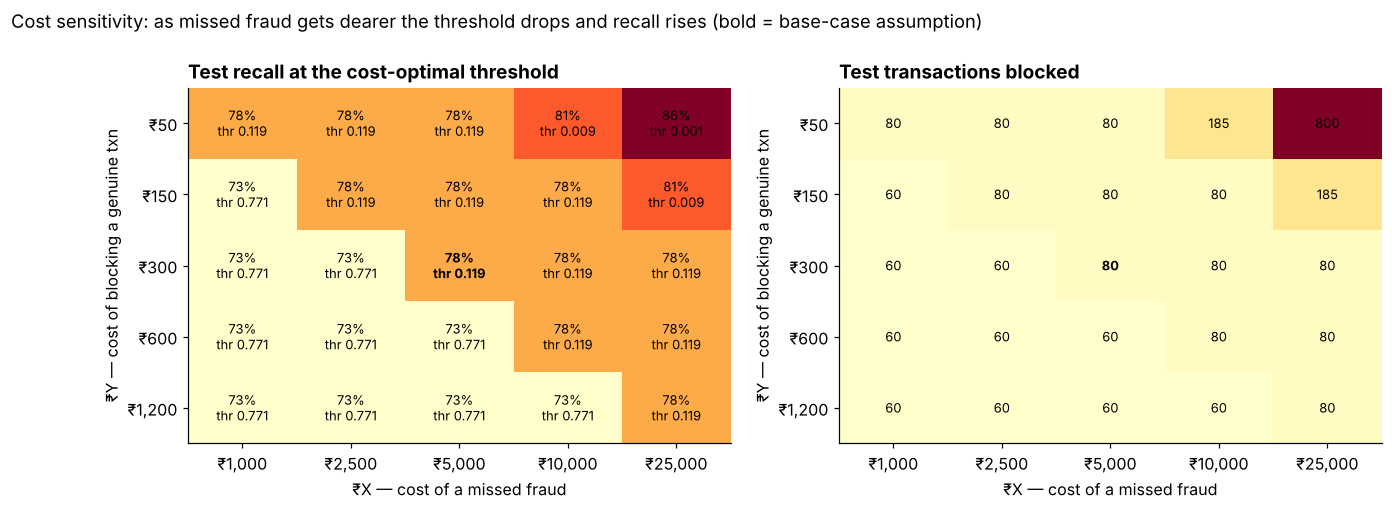

In [19]:
Xs, Ys = [1000, 2500, 5000, 10000, 25000], [50, 150, 300, 600, 1200]
grid_thr, grid_rec, grid_flag = np.zeros((len(Ys), len(Xs))), np.zeros((len(Ys), len(Xs))), np.zeros((len(Ys), len(Xs)))
for a, Yv in enumerate(Ys):
    for b, Xv in enumerate(Xs):
        c_ = L.CostConfig(X=Xv, Y=Yv, Z=COST.Z, otp_stop_rate=COST.otp_stop_rate)
        t_, _ = L.best_binary_threshold(yva, sv, c_)
        mm = L.binary_metrics(yte, st_, t_, c_)
        grid_thr[a, b], grid_rec[a, b], grid_flag[a, b] = t_, mm["recall"], mm["tp"] + mm["fp"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, G, t, fmt in [(axes[0], grid_rec, "Test recall at the cost-optimal threshold", "{:.0%}"), (axes[1], grid_flag, "Test transactions blocked", "{:,.0f}")]:
    ax.grid(False); im = ax.imshow(G, cmap="YlOrRd", aspect="auto")
    for i in range(len(Ys)):
        for j in range(len(Xs)):
            ax.text(j, i, fmt.format(G[i, j]) + (f"\nthr {grid_thr[i, j]:.3f}" if ax is axes[0] else ""), ha="center", va="center", fontsize=8.5,
                    fontweight="bold" if (Xs[j] == COST.X and Ys[i] == COST.Y) else "normal")
    ax.set_xticks(range(len(Xs))); ax.set_xticklabels([f"₹{v:,}" for v in Xs]); ax.set_yticks(range(len(Ys))); ax.set_yticklabels([f"₹{v:,}" for v in Ys])
    ax.set_xlabel("₹X — cost of a missed fraud"); ax.set_ylabel("₹Y — cost of blocking a genuine txn"); ax.set_title(t)
fig.suptitle("Cost sensitivity: as missed fraud gets dearer the threshold drops and recall rises (bold = base-case assumption)", x=0.01, y=1.0, va="bottom", ha="left", fontsize=12)
L.savefig(fig, "10_cost_sensitivity.png", FIG); plt.show()
SUMMARY["sensitivity"] = dict(X=Xs, Y=Ys, thr=grid_thr.round(4).tolist(), recall=grid_rec.round(3).tolist(), flagged=grid_flag.tolist())

## 8 · Risk-score decision rule: approve / step-up OTP / block (PS7) — owner: M. Suman Srinivas
Two thresholds `T_otp < T_block` are grid-searched on **validation** to minimise total cost:

* **APPROVE** (score < T_otp): fraud costs ₹X.
* **STEP-UP OTP** (T_otp ≤ score < T_block): every transaction costs ₹Z of friction. OTP stops an assumed 70% of fraud; the 30%
  that passes (e.g. a socially-engineered victim who types the OTP) still costs ₹X.
* **BLOCK** (score ≥ T_block): a genuine transaction costs ₹Y; a fraud costs ₹0.

The scores are also mapped to a 0–100 **risk score** with isotonic calibration fitted on validation.

T_otp = 0.00949  T_block = 0.77107  (validation cost ₹61,645)
Calibrated risk at T_otp ≈ 1.0/100, at T_block ≈ 88.9/100
Brier score (test): raw 0.00043 → calibrated 0.00043
TEST period (thresholds frozen from validation):


,band,transactions,pct_of_txns,frauds,pct_of_all_fraud,genuine,fraud_rate_in_band_pct,cost_from_fraud,cost_from_genuine,total_cost
0,APPROVE,56561,99.674%,14,18.9%,56547,0.02%,"₹70,000",₹0,"₹70,000"
1,STEP-UP OTP,125,0.220%,6,8.1%,119,4.80%,"₹9,090","₹1,785","₹10,875"
2,BLOCK,60,0.106%,54,73.0%,6,90.00%,₹0,"₹1,800","₹1,800"


,test_cost,saving_vs_no_model,cost_per_1M_txns (scenario)
Approve everything (no model),"₹370,000",₹0,"₹6,520,283"
Model @ default 0.5 (block/approve),"₹92,700","₹277,300","₹1,633,595"
Model @ cost threshold (block/approve),"₹86,600","₹283,400","₹1,526,099"
3-band rule (approve / OTP / block),"₹82,675","₹287,325","₹1,456,931"


Cost-optimal policy on test: 3-band rule (approve / OTP / block) | saving vs no model: ₹2.87 L
Bayes cross-check on calibrated probability: OTP above 0.43%, BLOCK above 15.8%  (empirical thresholds sit at calibrated 0.99% and 88.9%)


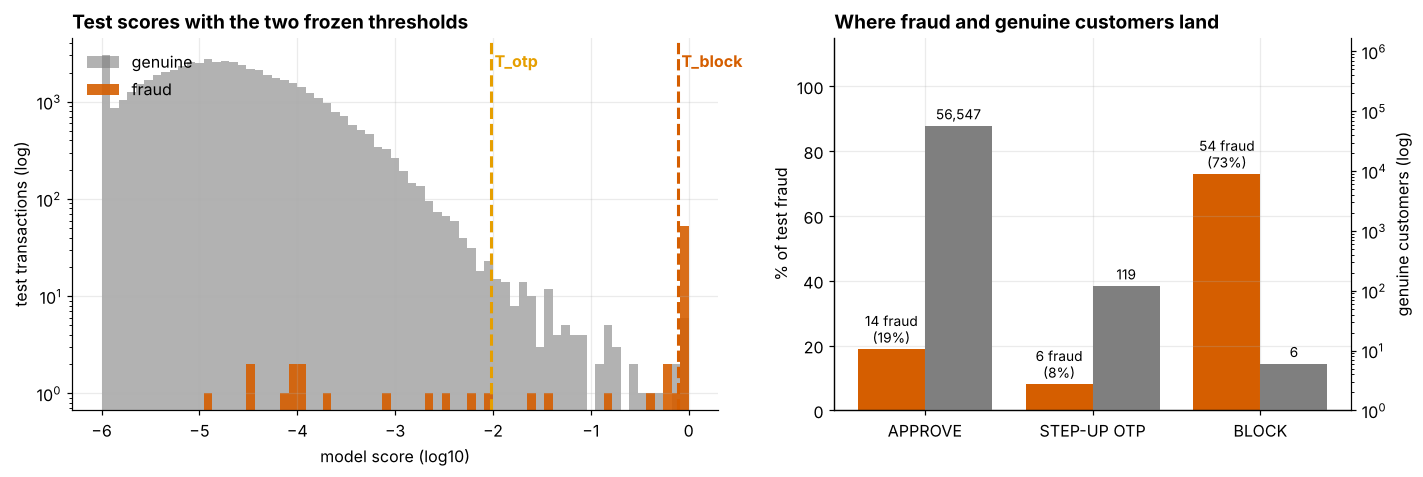

In [20]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss
cost_b, T_OTP, T_BLOCK = L.optimise_bands(yva, sv, COST, n_grid=400)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(sv, yva)
print(f"T_otp = {T_OTP:.5f}  T_block = {T_BLOCK:.5f}  (validation cost {L.inr(cost_b)})")
print(f"Calibrated risk at T_otp ≈ {100*iso.predict([T_OTP])[0]:.1f}/100, at T_block ≈ {100*iso.predict([T_BLOCK])[0]:.1f}/100")
print(f"Brier score (test): raw {brier_score_loss(yte, np.clip(st_,0,1)):.5f} → calibrated {brier_score_loss(yte, iso.predict(st_)):.5f}")
bands_val = L.band_costs(yva, sv, T_OTP, T_BLOCK, COST)
bands_te = L.band_costs(yte, st_, T_OTP, T_BLOCK, COST)
fmt = {"pct_of_txns": "{:.3f}%", "pct_of_all_fraud": "{:.1f}%", "fraud_rate_in_band_pct": "{:.2f}%",
       "cost_from_fraud": "₹{:,.0f}", "cost_from_genuine": "₹{:,.0f}", "total_cost": "₹{:,.0f}"}
print("TEST period (thresholds frozen from validation):"); display(bands_te.style.format(fmt))
bands_te.to_csv(os.path.join(TAB, "risk_bands_test.csv"), index=False)

policies = {
    "Approve everything (no model)": approve_all_cost,
    "Model @ default 0.5 (block/approve)": m_def["cost_inr"],
    "Model @ cost threshold (block/approve)": m_cost["cost_inr"],
    "3-band rule (approve / OTP / block)": bands_te.total_cost.sum(),
}
pol = pd.DataFrame({"test_cost": policies}); pol["saving_vs_no_model"] = approve_all_cost - pol.test_cost
pol["cost_per_1M_txns (scenario)"] = pol.test_cost / len(yte) * 1e6
display(pol.style.format("₹{:,.0f}"))
best_pol = pol.test_cost.idxmin()
print("Cost-optimal policy on test:", best_pol, "| saving vs no model:", L.inr(pol.loc[best_pol, "saving_vs_no_model"]))
if pol.loc["3-band rule (approve / OTP / block)", "test_cost"] >= approve_all_cost:
    print("→ No model-driven rule beats approving everything: with no signal, every block or OTP is pure customer friction.")
SUMMARY["bands"] = dict(T_otp=T_OTP, T_block=T_BLOCK, risk_otp=float(100 * iso.predict([T_OTP])[0]), risk_block=float(100 * iso.predict([T_BLOCK])[0]),
                        val=bands_val.to_dict("records"), test=bands_te.to_dict("records"))
# Theory cross-check: with calibrated p, OTP beats approve when p·X·stop > Z; block beats OTP when (1-p)·Y < Z + p·(1-stop)·X
p_otp = COST.Z / (COST.X * COST.otp_stop_rate); p_blk = (COST.Y - COST.Z) / (COST.Y + (1 - COST.otp_stop_rate) * COST.X)
print(f"Bayes cross-check on calibrated probability: OTP above {p_otp:.2%}, BLOCK above {p_blk:.1%}  "
      f"(empirical thresholds sit at calibrated {iso.predict([T_OTP])[0]:.2%} and {iso.predict([T_BLOCK])[0]:.1%})")
SUMMARY["bayes_bands"] = dict(p_otp=p_otp, p_block=p_blk)
SUMMARY["policies_test"] = pol.to_dict("index"); SUMMARY["n_test"] = int(len(yte)); SUMMARY["test_frauds"] = int(yte.sum())
SUMMARY["test_days"] = float((Xte[ds.time_col].max() - Xte[ds.time_col].min()) / 86400)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axes[0]
risk = 100 * iso.predict(st_); s_plot = np.log10(np.clip(st_, 1e-6, 1))
bins = np.linspace(s_plot.min(), 0, 70)
ax.hist(s_plot[yte == 0], bins, color=L.C["genuine"], alpha=0.6, label="genuine"); ax.hist(s_plot[yte == 1], bins, color=L.C["fraud"], alpha=0.9, label="fraud")
ax.set_yscale("log")
for t, lab, c in [(T_OTP, "T_otp", L.C["accent"]), (T_BLOCK, "T_block", L.C["fraud"])]:
    ax.axvline(np.log10(max(t, 1e-6)), color=c, lw=2, ls="--"); ax.text(np.log10(max(t, 1e-6)), ax.get_ylim()[1] * 0.5, f" {lab}", color=c, fontweight="bold")
ax.set_xlabel("model score (log10)"); ax.set_ylabel("test transactions (log)"); ax.legend(loc="upper left")
ax.set_title("Test scores with the two frozen thresholds")
ax = axes[1]
bt = bands_te.set_index("band")
x = np.arange(3)
ax.bar(x - 0.2, bt.pct_of_all_fraud, 0.4, color=L.C["fraud"], label="% of all fraud")
ax2 = ax.twinx(); ax2.bar(x + 0.2, np.maximum(bt.genuine, 1), 0.4, color=L.C["genuine"], label="genuine customers"); ax2.set_yscale("log"); ax2.grid(False)
ax2.set_ylim(1, max(bt.genuine.max(), 10) * 30)
ax2.spines["right"].set_visible(True); ax2.set_ylabel("genuine customers (log)")
for i, b in enumerate(bt.index):
    ax.text(i - 0.2, bt.pct_of_all_fraud[b] + 2, f"{bt.frauds[b]} fraud\n({bt.pct_of_all_fraud[b]:.0f}%)", ha="center", fontsize=9)
    ax2.text(i + 0.2, bt.genuine[b] * 1.3, f"{bt.genuine[b]:,}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(bt.index); ax.set_ylim(0, 115); ax.set_ylabel("% of test fraud")
ax.set_title("Where fraud and genuine customers land")
L.savefig(fig, "11_risk_bands.png", FIG); plt.show()

### Stress-testing the OTP assumptions (₹Z and the OTP stop rate)
The two thresholds are re-optimised on validation for every (₹Z, stop-rate) pair, then scored on test.

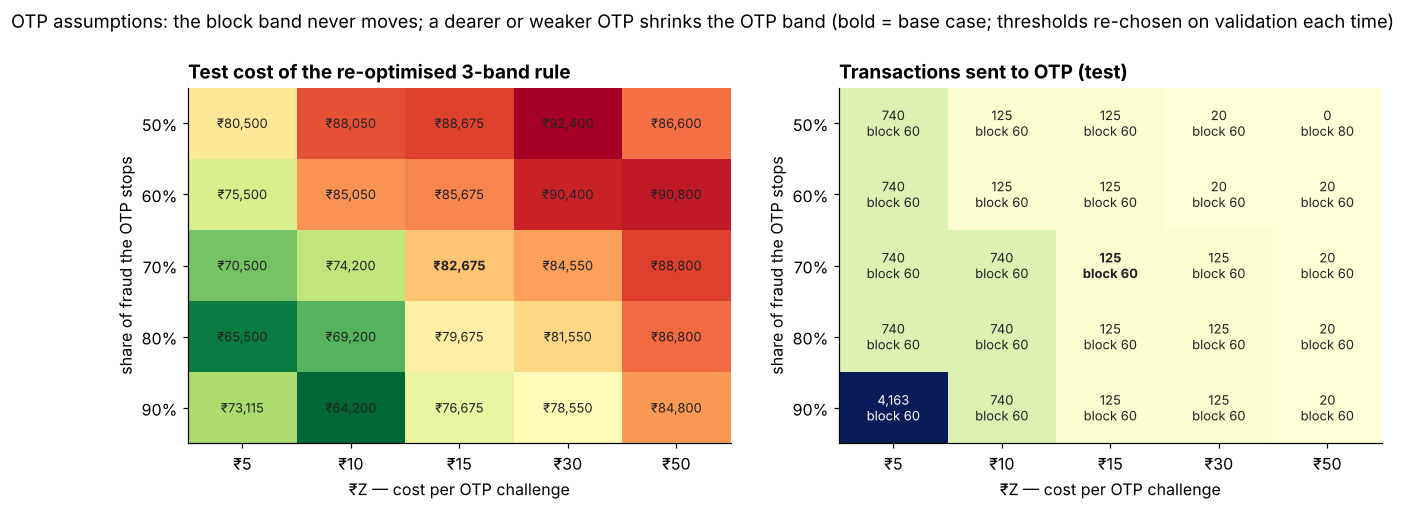

In [21]:
Zs, stops = [5, 10, 15, 30, 50], [0.5, 0.6, 0.7, 0.8, 0.9]
g_cost, g_otp, g_blk = (np.zeros((len(stops), len(Zs))) for _ in range(3))
for i, sr in enumerate(stops):
    for j, z in enumerate(Zs):
        c_ = L.CostConfig(X=COST.X, Y=COST.Y, Z=z, otp_stop_rate=sr)
        _, a_, b_ = L.optimise_bands(yva, sv, c_, n_grid=400)
        bt_ = L.band_costs(yte, st_, a_, b_, c_).set_index("band")
        g_cost[i, j], g_otp[i, j], g_blk[i, j] = bt_.total_cost.sum(), bt_.loc["STEP-UP OTP", "transactions"], bt_.loc["BLOCK", "transactions"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, G, t, f_ in [(axes[0], g_cost, "Test cost of the re-optimised 3-band rule", L.inr), (axes[1], g_otp, "Transactions sent to OTP (test)", lambda v: f"{v:,.0f}")]:
    ax.grid(False); ax.imshow(G if ax is axes[1] else -G, cmap="YlGnBu" if ax is axes[1] else "RdYlGn", aspect="auto")
    for a in range(len(stops)):
        for b in range(len(Zs)):
            dark = ax is axes[1] and G[a, b] > np.percentile(G, 90)
            ax.text(b, a, f_(G[a, b]) + (f"\nblock {g_blk[a, b]:.0f}" if ax is axes[1] else ""), ha="center", va="center", fontsize=8.5, color="white" if dark else L.C["ink"],
                    fontweight="bold" if (Zs[b] == COST.Z and stops[a] == COST.otp_stop_rate) else "normal")
    ax.set_xticks(range(len(Zs))); ax.set_xticklabels([f"₹{z}" for z in Zs]); ax.set_yticks(range(len(stops))); ax.set_yticklabels([f"{s_:.0%}" for s_ in stops])
    ax.set_xlabel("₹Z — cost per OTP challenge"); ax.set_ylabel("share of fraud the OTP stops"); ax.set_title(t)
fig.suptitle("OTP assumptions: the block band never moves; a dearer or weaker OTP shrinks the OTP band (bold = base case; thresholds re-chosen on validation each time)" if HAS_SIGNAL
             else "OTP assumptions: with no signal, no setting makes the rule beat approve-all", x=0.01, y=1.0, va="bottom", ha="left", fontsize=12)
L.savefig(fig, "10b_otp_sensitivity.png", FIG); plt.show()
SUMMARY["otp_sensitivity"] = dict(Z=Zs, stop=stops, test_cost=g_cost.tolist(), otp_n=g_otp.tolist(), block_n=g_blk.tolist())

### Where the money goes: from "approve everything" to the 3-band rule (test period, observed counts × assumed ₹)

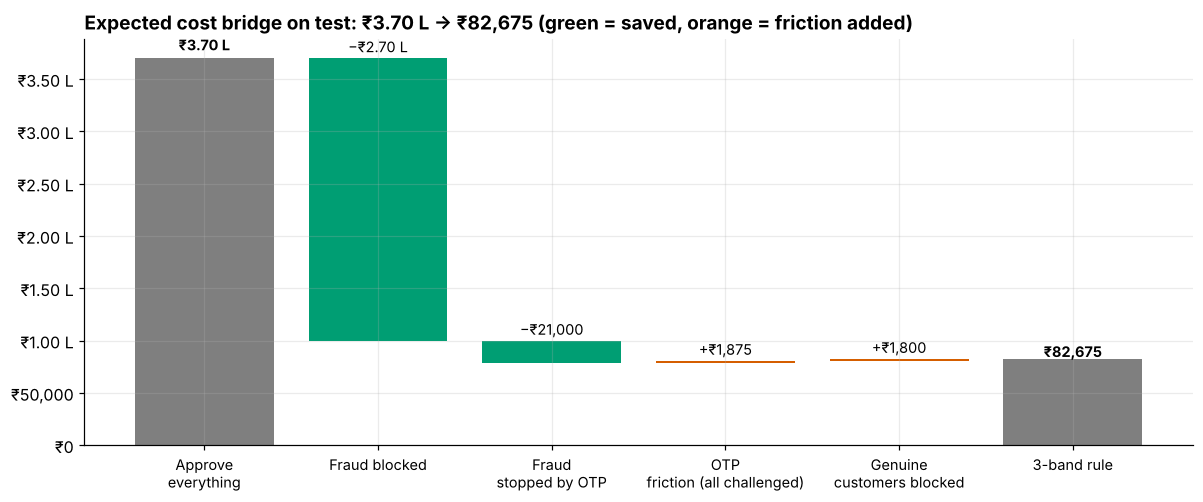

,band,fraud_value,genuine_value,share_of_fraud_value_pct
0,APPROVE,2385.48,4406959.28,30.87
1,STEP-UP OTP,1249.82,21733.31,16.17
2,BLOCK,4092.37,25696.24,52.96


3-band test cost ₹82,675 (95% CI ₹51,837–₹1.15 L). Scenario estimate per 1M txns: ₹14.57 L vs ₹65.20 L with no model → saving ≈ ₹50.63 L


In [22]:
bt = bands_te.set_index("band")
F_blk, F_otp, G_otp, G_blk = bt.loc["BLOCK", "frauds"], bt.loc["STEP-UP OTP", "frauds"], bt.loc["STEP-UP OTP", "genuine"], bt.loc["BLOCK", "genuine"]
steps = [("Approve everything", approve_all_cost, "total"),
         ("Fraud blocked", -F_blk * COST.X, "down"),
         ("Fraud stopped by OTP", -F_otp * COST.otp_stop_rate * COST.X, "down"),
         ("OTP friction (all challenged)", (F_otp + G_otp) * COST.Z, "up"),
         ("Genuine customers blocked", G_blk * COST.Y, "up")]
final_c = sum(v for _, v, _ in steps)
steps.append(("3-band rule", final_c, "total"))
assert abs(final_c - bands_te.total_cost.sum()) < 1, "waterfall must tie to band costs"
fig, ax = plt.subplots(figsize=(13, 4.8)); run = 0
for k, (lab, v, kind) in enumerate(steps):
    if kind == "total":
        ax.bar(k, v, color=L.C["genuine"]); ax.text(k, v * 1.02, L.inr(v), ha="center", fontsize=9.5, fontweight="bold"); run = v
    else:
        base = run + min(v, 0); ax.bar(k, abs(v), bottom=base, color=L.C["good"] if v < 0 else L.C["fraud"])
        ax.text(k, base + abs(v) + approve_all_cost * 0.015, ("−" if v < 0 else "+") + L.inr(abs(v)), ha="center", fontsize=9.5); run += v
ax.set_xticks(range(len(steps))); ax.set_xticklabels([s_[0].replace(" ", "\n", 1) if len(s_[0]) > 14 else s_[0] for s_ in steps], fontsize=9.5)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: L.inr(v)))
ax.set_title(f"Expected cost bridge on test: {L.inr(approve_all_cost)} → {L.inr(final_c)} (green = saved, orange = friction added)")
L.savefig(fig, "11b_cost_waterfall.png", FIG); plt.show()

# value view: how much transaction value sits in each band (source currency units, not rupees)
amt_te = Xte["amount"].values
val_rows = []
for b_, m_ in [("APPROVE", st_ < T_OTP), ("STEP-UP OTP", (st_ >= T_OTP) & (st_ < T_BLOCK)), ("BLOCK", st_ >= T_BLOCK)]:
    val_rows.append(dict(band=b_, fraud_value=float(amt_te[m_ & (yte == 1)].sum()), genuine_value=float(amt_te[m_ & (yte == 0)].sum())))
val_df = pd.DataFrame(val_rows); val_df["share_of_fraud_value_pct"] = 100 * val_df.fraud_value / max(val_df.fraud_value.sum(), 1e-9)
display(val_df.round(2))
SUMMARY["band_value"] = val_df.round(2).to_dict("records")

# bootstrap CI of the 3-band cost and of the per-1M projection (scenario estimate)
def _band_total(y_, s_): return L.band_costs(y_, s_, T_OTP, T_BLOCK, COST).total_cost.sum()
ci_band = L.bootstrap_ci(yte, st_, _band_total, n_boot=300)
proj = dict(per_1m_three_band=final_c / len(yte) * 1e6, per_1m_ci=[c / len(yte) * 1e6 for c in ci_band],
            per_1m_no_model=approve_all_cost / len(yte) * 1e6)
proj["per_1m_saving"] = proj["per_1m_no_model"] - proj["per_1m_three_band"]
print(f"3-band test cost {L.inr(final_c)} (95% CI {L.inr(ci_band[0])}–{L.inr(ci_band[1])}). Scenario estimate per 1M txns: "
      f"{L.inr(proj['per_1m_three_band'])} vs {L.inr(proj['per_1m_no_model'])} with no model → saving ≈ {L.inr(proj['per_1m_saving'])}")
SUMMARY["three_band_ci"] = ci_band; SUMMARY["projection"] = proj

## 9 · Explaining the final model (PS8) — owner: M. Suman Srinivas
The final model is explained with **TreeSHAP** in **log-odds (raw margin)** space, using the exact tree-path-dependent algorithm.
Explanation rows: every test fraud plus 3,000 random test genuines (seed 42). Additivity is checked against `predict(raw_score=True)`.
If the selected model is an ensemble, we explain its strongest GBDT member. SHAP describes **how the model uses features, not what
causes fraud**.

Explained model: CatBoost | class weights | output: log-odds of fraud | rows: 3074 (74 fraud) | max additivity error 6.04e-14


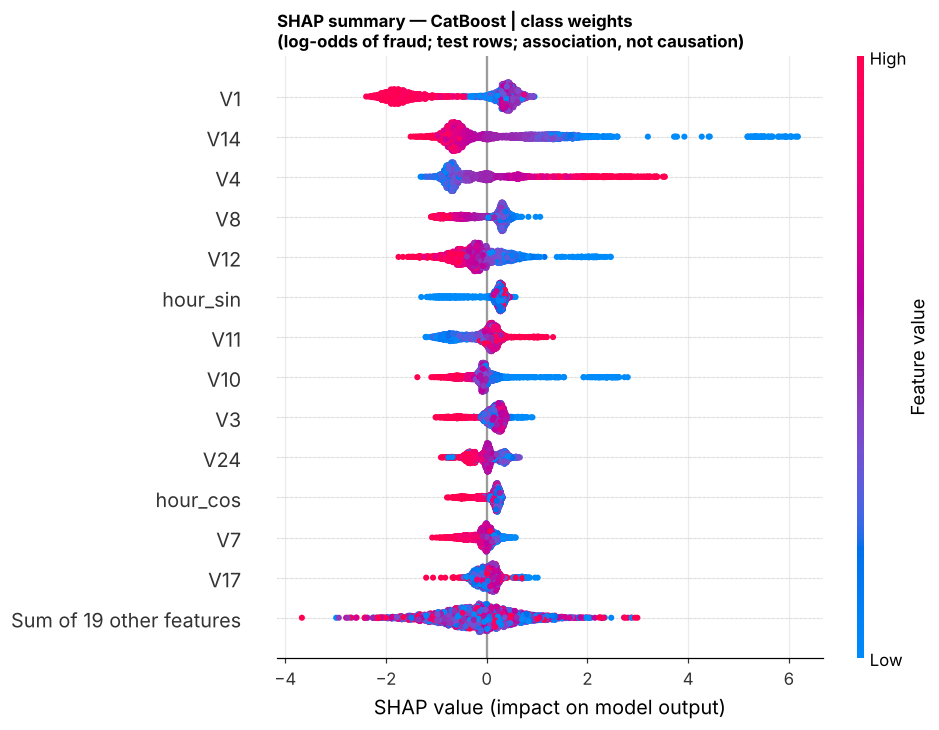

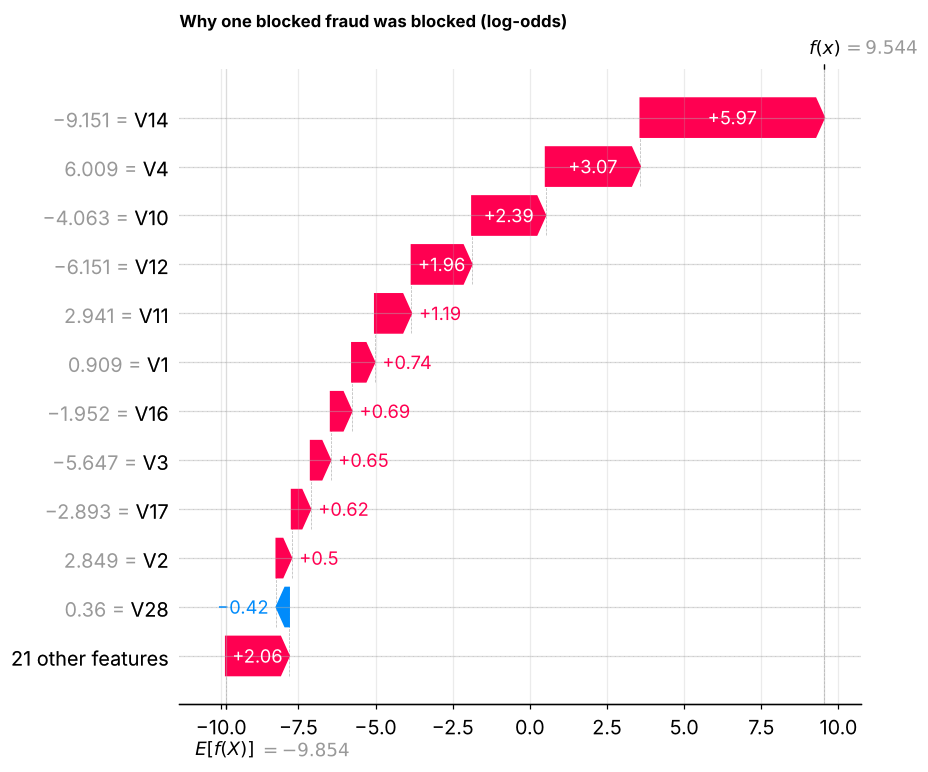

,mean |SHAP| (log-odds)
V1,0.9606
V14,0.8602
V4,0.6836
V8,0.3975
V12,0.3882
hour_sin,0.3087
V11,0.2975
V10,0.2396
V3,0.2187
V24,0.2110


In [23]:
import shap
gbdt_like = lambda k: k in FITTED and any(t in k for t in ["LightGBM", "XGBoost", "Hybrid", "CatBoost"])
EXPLAIN = FINAL if gbdt_like(FINAL) else next(k for k in top3 + list(cmp.model) if gbdt_like(k))
pipe = FITTED[EXPLAIN]; is_h = EXPLAIN.startswith("Hybrid")
Xte_e = Xte_h if is_h else Xte
rng = np.random.default_rng(L.SEED)
rows_e = np.sort(np.r_[np.where(yte == 1)[0], rng.choice(np.where(yte == 0)[0], 3000, replace=False)])
Xp = pd.DataFrame(pipe.named_steps["pre"].transform(Xte_e.iloc[rows_e]), columns=pipe.named_steps["pre"].get_feature_names_out())
clf = pipe.named_steps["clf"]
expl = shap.TreeExplainer(clf, feature_perturbation="tree_path_dependent", model_output="raw")
ex = expl(Xp)
if ex.values.ndim == 3: ex = ex[..., 1]
if hasattr(clf, "booster_"): raw = clf.predict(Xp.values, raw_score=True)                      # LightGBM
elif "CatBoost" in type(clf).__name__: raw = clf.predict(Xp.values, prediction_type="RawFormulaVal")
else: raw = clf.predict(Xp.values, output_margin=True)                                           # XGBoost
add_err = float(np.abs(np.asarray(ex.base_values) + ex.values.sum(1) - raw).max())
print(f"Explained model: {EXPLAIN} | output: log-odds of fraud | rows: {len(rows_e)} ({int(yte[rows_e].sum())} fraud) | max additivity error {add_err:.2e}")
assert add_err < 1e-3, "SHAP additivity failed — check preprocessing/feature order"
imp = pd.Series(np.abs(ex.values).mean(0), index=Xp.columns).sort_values(ascending=False)
SUMMARY["shap"] = dict(model=EXPLAIN, top=imp.head(10).round(4).to_dict(), additivity_err=add_err)

plt.figure(); shap.plots.beeswarm(ex, max_display=14, show=False)
plt.title(f"SHAP summary — {EXPLAIN}\n(log-odds of fraud; test rows; association, not causation)", loc="left", fontsize=11)
plt.gcf().savefig(os.path.join(FIG, "12_shap_beeswarm.png"), bbox_inches="tight"); plt.show()
# local explanation: the highest-scoring test fraud that the rule BLOCKS
fr_rows = np.where(yte[rows_e] == 1)[0]; i_top = fr_rows[np.argmax(raw[fr_rows])]
plt.figure(); shap.plots.waterfall(ex[i_top], max_display=12, show=False)
plt.title("Why one blocked fraud was blocked (log-odds)", loc="left", fontsize=11)
plt.gcf().savefig(os.path.join(FIG, "13_shap_waterfall.png"), bbox_inches="tight"); plt.show()
display(imp.head(12).to_frame("mean |SHAP| (log-odds)").round(4))

### Save artefacts for the Streamlit demo, and the run summary

In [24]:
bundle = dict(dataset=DATASET, final=FINAL, explain_model=EXPLAIN, pipeline=FITTED.get(FINAL, pipe), shap_pipeline=pipe,
              is_hybrid=FINAL.startswith("Hybrid"), hybrid_features=HYB_FEATS,
              anomaly_detectors={k: ANOM[k]["det"] for k in HYB_FEATS} if FINAL.startswith("Hybrid") else None,
              ensemble=({k: FITTED[k] for k in top3} if FINAL.startswith("Ensemble") else None),
              T_otp=T_OTP, T_block=T_BLOCK, T_cost=T_COST, calibrator=iso, costs=COST.__dict__, features=ds.features, cat_features=ds.cat_features,
              num_features=ds.num_features)
if DATASET == "creditcard":
    joblib.dump(bundle, os.path.join(MODELS, "fraudguard_creditcard.joblib"))
    demo = Xte.iloc[np.r_[np.where(yte == 1)[0], rng.choice(np.where(yte == 0)[0], 400, replace=False)]].copy()
    demo[["Time", "Amount", "Class"] + [f"V{i}" for i in range(1, 29)]].to_csv(os.path.join(ROOT, "app", "demo_transactions.csv"), index=False)
with open(os.path.join(ROOT, "outputs", f"summary_{DATASET}.json"), "w") as f:
    json.dump(SUMMARY, f, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else (float(o) if isinstance(o, (np.floating, np.integer)) else str(o)))
print("saved summary + artefacts")

saved summary + artefacts


### Export for the web app (FraudGuard on Netlify)
The CatBoost model is exported as JSON so the browser can score transactions and compute exact TreeSHAP with no server.
For UPI, the CatBoost model is exported too, but the app enforces the evidence-based policy: **approve everything**, because
the model has no signal.

In [25]:
WEB = os.path.join(ROOT, "web", "models"); os.makedirs(WEB, exist_ok=True)
WEB_MODEL = FINAL if "CatBoost" in FINAL else "CatBoost | class weights"
wpipe = FITTED[WEB_MODEL]; wpre, wclf = wpipe.named_steps["pre"], wpipe.named_steps["clf"]
wclf.save_model(os.path.join(WEB, f"catboost_{DATASET}.json"), format="json")
w_sv, w_st = SCORES[WEB_MODEL]["val"], SCORES[WEB_MODEL]["test"]
if WEB_MODEL == FINAL: w_to, w_tb, w_iso = T_OTP, T_BLOCK, iso
else:
    _, w_to, w_tb = L.optimise_bands(yva, w_sv, COST, n_grid=400); w_iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(w_sv, yva)
def top_slice(y_, s_, frac=0.05):
    k = int(np.ceil(frac * len(s_))); o = np.argsort(-s_, kind="stable")[:k]
    return dict(scores=np.round(s_[o], 7).tolist(), labels=y_[o].astype(int).tolist(), n=int(len(s_)), n_fraud=int(y_.sum()), cutoff=float(s_[o[-1]]))
cats = {}
if ds.cat_features:
    ohe = wpre.named_transformers_["cat"]
    cats = {c: [str(v) for v in cv] for c, cv in zip(ds.cat_features, ohe.categories_)}
rng_w = np.random.default_rng(L.SEED)
demo_ix = np.r_[np.where(yte == 1)[0], rng_w.choice(np.where(yte == 0)[0], 200, replace=False)]
raw_cols = (["Time", "Amount"] + [f"V{i}" for i in range(1, 29)]) if DATASET == "creditcard" else \
           ["transaction type", "merchant_category", "amount (INR)", "sender_age_group", "receiver_age_group", "sender_state", "sender_bank",
            "receiver_bank", "device_type", "network_type", "hour_of_day", "day_of_week", "is_weekend"]
demo = Xte.iloc[demo_ix][raw_cols].copy(); demo["label"] = yte[demo_ix]; demo["py_score"] = w_st[demo_ix]
web_spec = dict(
    dataset=DATASET, model=WEB_MODEL, final_model=FINAL, has_signal=bool(HAS_SIGNAL), policy=("three_band" if HAS_SIGNAL else "approve_all"),
    feature_order=list(wpre.get_feature_names_out()), num_features=ds.num_features, cat_features=cats,
    thresholds=dict(T_otp=float(min(w_to, 2.0)), T_block=float(min(w_tb, 2.0)), T_cost=float(min(T_COST, 2.0))), costs=COST.__dict__,   # 2.0 = "never" (scores ≤ 1); JSON has no Infinity
    calibrator=dict(x=np.round(w_iso.X_thresholds_, 8).tolist(), y=np.round(w_iso.y_thresholds_, 6).tolist()),
    search=dict(val=top_slice(yva, w_sv), test=top_slice(yte, w_st)),
    metrics=dict(test_pr_auc=float(average_precision_score(yte, w_st)), test_roc_auc=float(roc_auc_score(yte, w_st)),
                 base_rate=float(yte.mean()), signal_p=sig["test"]["p_value"]),
    test_bands=L.band_costs(yte, w_st, w_to, w_tb, COST).round(4).to_dict("records"),
    policies={k: float(v["test_cost"]) for k, v in pol.to_dict("index").items()},
    comparison=cmp[["model", "family", "imbalance", "val_pr_auc", "test_pr_auc", "test_roc_auc", "test_precision", "test_recall", "test_cost"]].round(4).to_dict("records"),
    anomaly=anom_tbl.round(4).to_dict("records"), split=split_df.to_dict("records"),
    demo=json.loads(demo.to_json(orient="records")),
    trap=[dict(name=n_, **{k: float(v) for k, v in d_.items()}) for n_, d_ in
          [("Do-nothing (approve all)", do_nothing), (f"{FINAL} @ default 0.5", m_def), (f"{FINAL} @ cost threshold", m_cost)]],
    audit=ds.audit.to_dict("records"), excluded=ds.excluded.to_dict("records"),
    eda=json.loads(json.dumps(eda_findings, default=str)), shap_top=SUMMARY["shap"]["top"],
    n_rows=int(len(df)), n_fraud=int(y_all.sum()))
with open(os.path.join(WEB, f"{DATASET}.json"), "w") as f: json.dump(web_spec, f, default=float)
print("web export:", WEB_MODEL, "| T_otp", round(w_to, 5), "T_block", round(w_tb, 5), "| demo rows", len(demo))

web export: CatBoost | class weights | T_otp 0.00949 T_block 0.77107 | demo rows 274


## Findings, recommendations and limitations
The numbers for this section are generated in `outputs/summary_<dataset>.json`; the business report puts them into prose.
* **Observed:** everything above was measured on the frozen-threshold test period.
* **Projected:** "₹ per 1M transactions" figures are **scenario estimates** that depend on the assumed ₹X/₹Y/₹Z and on future traffic
  resembling the test period.
* **Limitations:** 2-day credit-card capture (European cardholders, September 2013; the source never states the currency of `Amount`, so rupee costs are applied per event, not as a share of the amount); PCA features
  block business-readable explanations; validation holds only ~57 frauds, so thresholds carry sampling noise (see the CIs); the UPI
  file is simulated, its label is unrelated to every column, and it has no account IDs.